
# RQ29B — Held-out characterization of frozen PhageLysClass recipes

## Question

**How do the individual members and final ensemble recipes frozen for production behave under a canonical held-out generalization condition?**

RQ29B characterizes the architecture produced by RQ29A/RQ28 without evaluating the final all-data refits on their fitting data.

### Evaluation basis

The canonical characterization condition is:

\[
R30/S30
\]

because it provides a stringent held-out regime already defined by the benchmark.

For each production task, this notebook:

1. audits the serialized RQ29A bundle and estimator health;
2. loads the frozen individual-member outer-test predictions at `R30/S30`;
3. validates each individual member against Stage12A;
4. reconstructs the final unweighted ensemble exactly from aligned member probabilities;
5. validates the reconstructed final recipe against the strict metric frozen in RQ28;
6. computes confusion matrices, ROC curves, Precision–Recall curves, and detailed performance tables;
7. exports `performance.json` for every production task;
8. generates paper/API-ready characterization artifacts.

### Critical interpretation

The curves and metrics below are **held-out estimates of the frozen recipe/strategy**, not measurements of the final all-data refit weights produced by RQ29A.

The final refit intentionally uses all eligible production evidence. Evaluating those fitted weights on the same evidence would be optimistic and is therefore not done.

A configuration-alignment audit records whether the `R30/S30` validation-selected configuration equals the production consensus configuration frozen by RQ29A. A mismatch is reported transparently but does not invalidate recipe-level held-out characterization.


In [1]:

from pathlib import Path
from datetime import datetime, timezone
from io import StringIO
from itertools import combinations, permutations
import hashlib
import json
import os
import re
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_recall_curve,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import label_binarize

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 320)
pd.set_option("display.max_rows", 400)

STRICT_R = 30
STRICT_S = 30
MCC_ATOL = 1e-10
PROBA_SUM_ATOL = 1e-6

MODEL_VERSION = "phagelysclass_v1"
REPRESENTATION_ID = "esm2_t30_150m"

PRODUCTION_TASKS = [
    "global_mixed",
    "multiclass_clean",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

TASK_SPECS = {
    "global_mixed": {
        "path": "global_mixed",
        "type": "binary",
        "positive_label": "lytic",
        "negative_label": "non-lytic/background",
    },
    "multiclass_clean": {
        "path": "multiclass_clean",
        "type": "multiclass",
    },
    "subtype_endolysin": {
        "path": "subtype_binary/endolysin",
        "type": "binary",
        "positive_label": "endolysin-compatible",
        "negative_label": "non-lytic/background",
    },
    "subtype_depolymerase": {
        "path": "subtype_binary/depolymerase",
        "type": "binary",
        "positive_label": "depolymerase-compatible",
        "negative_label": "non-lytic/background",
    },
    "subtype_val": {
        "path": "subtype_binary/virion_associated_lytic_enzyme",
        "type": "binary",
        "positive_label": "VAL-compatible",
        "negative_label": "non-lytic/background",
    },
}

MULTICLASS_ORDER = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]
MULTICLASS_DISPLAY = ["Endolysin", "Depolymerase", "VAL"]


def find_project_root(start=None):
    explicit = os.environ.get("PHAGELYSCLASS_ROOT")
    candidates = []
    if explicit:
        candidates.append(Path(explicit).expanduser().resolve())

    start = Path.cwd() if start is None else Path(start)
    candidates.extend([start, *start.parents])

    seen = set()
    for root in candidates:
        root = root.resolve()
        if root in seen:
            continue
        seen.add(root)
        if (
            (root / "models/phagelysclass_v1/manifest.json").is_file()
            and (root / "results/analysis_deployment/rq29a/rq29a_config_consensus.tsv").is_file()
            and (root / "results/analysis_deployment/rq28/rq28_frozen_components.tsv").is_file()
            and (root / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file()
            and (root / "results/training_supervised").is_dir()
        ):
            return root

    raise FileNotFoundError(
        "Could not locate project root with RQ29A production bundle, RQ28 freeze, "
        "Stage12A, and training outputs."
    )


ROOT = find_project_root()

MODEL_ROOT = ROOT / "models" / MODEL_VERSION
RQ29A_DIR = ROOT / "results/analysis_deployment/rq29a"
RQ28_DIR = ROOT / "results/analysis_deployment/rq28"
STAGE12A_DIR = ROOT / "results/analysis_supervised/stage12a"
SUP_CACHE = ROOT / "results/analysis_supervised/notebook_cache"
TRAINING_ROOT = ROOT / "results/training_supervised"

RQ29B_OUT = ROOT / "results/analysis_deployment/rq29b"
FIG_DIR = RQ29B_OUT / "figures"
RQ29B_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("MODEL_ROOT:", MODEL_ROOT)
print("RQ29B_OUT:", RQ29B_OUT)
print("Canonical held-out characterization: R30/S30")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
MODEL_ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/models/phagelysclass_v1
RQ29B_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq29b
Canonical held-out characterization: R30/S30


## 1. RQ29A production-bundle health audit

In [2]:

MODEL_MANIFEST_PATH = MODEL_ROOT / "manifest.json"
CHECKSUMS_PATH = MODEL_ROOT / "checksums.tsv"
RQ29A_MANIFEST_PATH = RQ29A_DIR / "rq29a_manifest.json"
RQ29A_CONSENSUS_PATH = RQ29A_DIR / "rq29a_config_consensus.tsv"
RQ29A_SELECTED_CELLS_PATH = RQ29A_DIR / "rq29a_selected_config_cells.tsv"
RQ28_COMPONENTS_PATH = RQ28_DIR / "rq28_frozen_components.tsv"

for p in [
    MODEL_MANIFEST_PATH,
    CHECKSUMS_PATH,
    RQ29A_MANIFEST_PATH,
    RQ29A_CONSENSUS_PATH,
    RQ29A_SELECTED_CELLS_PATH,
    RQ28_COMPONENTS_PATH,
]:
    if not p.is_file():
        raise FileNotFoundError(p)

model_manifest = json.loads(MODEL_MANIFEST_PATH.read_text(encoding="utf-8"))
rq29a_manifest = json.loads(RQ29A_MANIFEST_PATH.read_text(encoding="utf-8"))
frozen = pd.read_csv(RQ28_COMPONENTS_PATH, sep="\t", low_memory=False)
consensus = pd.read_csv(RQ29A_CONSENSUS_PATH, sep="\t", low_memory=False)
selected_cells = pd.read_csv(RQ29A_SELECTED_CELLS_PATH, sep="\t", low_memory=False)

assert model_manifest["architecture_id"] == "C_2_core_plus_3_aux"
assert model_manifest["production_global_task"] == "global_mixed"
assert model_manifest["n_fitted_estimators"] == 10
assert rq29a_manifest["status"] == "published"
assert rq29a_manifest["roundtrip_all_ok"] is True

frozen = (
    frozen[frozen["task"].isin(PRODUCTION_TASKS)]
    .copy()
    .set_index("task")
    .reindex(PRODUCTION_TASKS)
    .reset_index()
)

if len(frozen) != 5:
    raise RuntimeError("RQ28 production freeze must contain exactly five production tasks.")


def sha256_file(path, block_size=8 * 1024 * 1024):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(block_size), b""):
            h.update(block)
    return h.hexdigest()


checksums = pd.read_csv(CHECKSUMS_PATH, sep="\t", low_memory=False)
checksum_rows = []
for row in checksums.itertuples(index=False):
    p = MODEL_ROOT / row.relative_path
    observed = sha256_file(p) if p.is_file() else None
    checksum_rows.append({
        "relative_path": row.relative_path,
        "exists": p.is_file(),
        "expected_sha256": row.sha256,
        "observed_sha256": observed,
        "checksum_ok": bool(p.is_file() and observed == row.sha256),
    })

checksum_audit = pd.DataFrame(checksum_rows)
if not checksum_audit["checksum_ok"].all():
    raise RuntimeError(
        "RQ29A production bundle checksum mismatch:\n"
        + checksum_audit.loc[~checksum_audit["checksum_ok"]].to_string(index=False)
    )

print("RQ29A checksums:", int(checksum_audit["checksum_ok"].sum()), "/", len(checksum_audit))
print("RQ29A_BUNDLE_CHECKSUMS_OK")


RQ29A checksums: 30 / 30
RQ29A_BUNDLE_CHECKSUMS_OK



### Optimizer/convergence audit

RQ29A captured one or more fit warnings rather than sending them to `stderr`. RQ29B therefore inspects both the stored warning messages and fitted-estimator iteration state before any characterization is accepted.

A production estimator that visibly reaches its configured iteration ceiling is treated as a failed health gate.


In [3]:

health_rows = []

for task in PRODUCTION_TASKS:
    member_dir = MODEL_ROOT / "tasks" / task / "members"
    metadata_files = sorted(member_dir.glob("*.metadata.json"))
    model_files = sorted(member_dir.glob("*.joblib"))

    if len(metadata_files) != len(model_files):
        raise RuntimeError(
            f"{task}: model/metadata count mismatch: "
            f"{len(model_files)} models vs {len(metadata_files)} metadata files."
        )

    for metadata_path in metadata_files:
        meta = json.loads(metadata_path.read_text(encoding="utf-8"))
        model_path = member_dir / (metadata_path.name.replace(".metadata.json", ".joblib"))
        if not model_path.is_file():
            raise FileNotFoundError(model_path)

        model = joblib.load(model_path)
        estimator = model.named_steps["model"] if hasattr(model, "named_steps") else model

        n_iter = getattr(estimator, "n_iter_", None)
        max_iter = getattr(estimator, "max_iter", None)

        if n_iter is None:
            max_observed_iter = None
            optimizer_limit_hit = False
        else:
            arr = np.asarray(n_iter).astype(float).ravel()
            max_observed_iter = int(np.nanmax(arr))
            optimizer_limit_hit = bool(
                max_iter is not None and np.isfinite(max_iter)
                and max_observed_iter >= int(max_iter)
            )

        fit_warnings = meta.get("fit_warnings", []) or []
        warning_text = " | ".join(map(str, fit_warnings))
        convergence_keyword = bool(
            re.search(
                r"converg|maximum number of iterations|max_iter|iteration limit",
                warning_text,
                flags=re.IGNORECASE,
            )
        )

        health_ok = not optimizer_limit_hit and not convergence_keyword

        health_rows.append({
            "task": task,
            "algorithm": meta["algorithm"],
            "config_id": meta["config_id"],
            "fit_warning_count": int(meta.get("fit_warning_count", len(fit_warnings))),
            "fit_warnings": warning_text,
            "max_observed_iter": max_observed_iter,
            "configured_max_iter": max_iter,
            "optimizer_limit_hit": optimizer_limit_hit,
            "convergence_warning_detected": convergence_keyword,
            "health_ok": health_ok,
        })

model_health = pd.DataFrame(health_rows)
model_health.to_csv(
    RQ29B_OUT / "rq29b_production_model_health.tsv",
    sep="\t",
    index=False,
)

display(model_health)

bad_health = model_health[~model_health["health_ok"]]
if len(bad_health):
    raise RuntimeError(
        "A serialized production estimator failed the convergence/optimizer health gate. "
        "Patch/rebuild RQ29A before characterizing the release:\n"
        + bad_health.to_string(index=False)
    )

print("PRODUCTION_MODEL_HEALTH_OK")


,task,algorithm,config_id,fit_warning_count,fit_warnings,max_observed_iter,configured_max_iter,optimizer_limit_hit,convergence_warning_detected,health_ok
0,global_mixed,KNN,KNN02,0,,NaN,NaN,False,False,True
1,global_mixed,MLP,MLP02,0,,48.0,300.0,False,False,True
2,multiclass_clean,LR,LR01,1,'penalty' was deprecated in version 1.8 and wi...,91.0,2000.0,False,False,True
3,multiclass_clean,XGB,XGB01,0,,NaN,NaN,False,False,True
4,subtype_endolysin,KNN,KNN01,0,,NaN,NaN,False,False,True
5,subtype_endolysin,MLP,MLP02,0,,48.0,300.0,False,False,True
6,subtype_endolysin,XGB,XGB01,0,,NaN,NaN,False,False,True
7,subtype_depolymerase,KNN,KNN03,0,,NaN,NaN,False,False,True
8,subtype_depolymerase,MLP,MLP01,0,,28.0,300.0,False,False,True
9,subtype_val,MLP,MLP01,0,,20.0,300.0,False,False,True


PRODUCTION_MODEL_HEALTH_OK


## 2. Frozen recipes and strict-configuration alignment

In [4]:

def split_semicolon(value):
    return [x.strip() for x in str(value).split(";") if x.strip()]


member_rows = []
for row in frozen.to_dict("records"):
    strategies = split_semicolon(row["member_strategy_ids"])
    reps = split_semicolon(row["member_representations"])
    algs = split_semicolon(row["member_algorithms"])

    if not (len(strategies) == len(reps) == len(algs) == int(row["n_members"])):
        raise RuntimeError(f"RQ28 member-vector mismatch for {row['task']}")

    for idx, (strategy, rep, alg) in enumerate(zip(strategies, reps, algs), start=1):
        member_rows.append({
            "task": row["task"],
            "member_index": idx,
            "strategy_id": strategy,
            "representation": rep,
            "algorithm": alg,
            "option_type": row["option_type"],
            "voting_scheme": row["voting_scheme"],
            "tier": row["tier"],
        })

members = pd.DataFrame(member_rows)
assert len(members) == 10
assert set(members["representation"]) == {REPRESENTATION_ID}

strict_selected = selected_cells[
    selected_cells["R"].eq(STRICT_R)
    & selected_cells["S"].eq(STRICT_S)
][
    ["task", "representation", "algorithm", "selected_config_id"]
].copy().rename(columns={"selected_config_id": "strict_selected_config_id"})

production_consensus = consensus[
    ["task", "representation", "algorithm", "consensus_config_id"]
].copy().rename(columns={"consensus_config_id": "production_consensus_config_id"})

config_alignment = (
    members
    .merge(
        strict_selected,
        on=["task", "representation", "algorithm"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        production_consensus,
        on=["task", "representation", "algorithm"],
        how="left",
        validate="one_to_one",
    )
)

if config_alignment[
    ["strict_selected_config_id", "production_consensus_config_id"]
].isna().any().any():
    raise RuntimeError("Could not align strict and production configuration IDs.")

config_alignment["strict_matches_production_consensus"] = (
    config_alignment["strict_selected_config_id"].astype(str)
    == config_alignment["production_consensus_config_id"].astype(str)
)

config_alignment.to_csv(
    RQ29B_OUT / "rq29b_config_alignment.tsv",
    sep="\t",
    index=False,
)

display(config_alignment[[
    "task", "algorithm",
    "strict_selected_config_id",
    "production_consensus_config_id",
    "strict_matches_production_consensus",
]])

print(
    "Strict/production config matches:",
    int(config_alignment["strict_matches_production_consensus"].sum()),
    "/",
    len(config_alignment),
)
print("CONFIG_ALIGNMENT_AUDITED")


,task,algorithm,strict_selected_config_id,production_consensus_config_id,strict_matches_production_consensus
0,global_mixed,KNN,KNN03,KNN02,False
1,global_mixed,MLP,MLP03,MLP02,False
2,multiclass_clean,XGB,XGB03,XGB01,False
3,multiclass_clean,LR,LR01,LR01,True
4,subtype_endolysin,KNN,KNN01,KNN01,True
5,subtype_endolysin,XGB,XGB01,XGB01,True
6,subtype_endolysin,MLP,MLP02,MLP02,True
7,subtype_depolymerase,MLP,MLP02,MLP01,False
8,subtype_depolymerase,KNN,KNN02,KNN03,False
9,subtype_val,MLP,MLP02,MLP01,False


Strict/production config matches: 4 / 10
CONFIG_ALIGNMENT_AUDITED


## 3. Locate strict held-out prediction artifacts and validate individual members

In [5]:

STAGE12A_MASTER_PATH = STAGE12A_DIR / "supervised_master_results.tsv"
master = pd.read_csv(STAGE12A_MASTER_PATH, sep="\t", low_memory=False)

required_master = {"task", "R", "S", "representation", "algorithm", "mcc"}
missing_master = required_master - set(master.columns)
if missing_master:
    raise KeyError(f"Stage12A master missing {sorted(missing_master)}")
if len(master) != 2240:
    raise RuntimeError(f"Expected 2,240 Stage12A experiment families; observed {len(master)}.")


def experiment_dir(task, representation, algorithm):
    return (
        TRAINING_ROOT
        / TASK_SPECS[task]["path"]
        / f"R{STRICT_R}_S{STRICT_S}"
        / representation
        / algorithm
    )



MULTI_PROBABILITY_ALIASES = {
    "endolysin": {
        "p_endolysin",
    },
    "depolymerase": {
        "p_depolymerase",
    },
    "val": {
        "p_val",
        "p_virion_associated_lytic_enzyme",
        "p_virion_associated_lytic_enzyme_val",
    },
}


def canonical_subtype_from_text(value):
    s = str(value).strip().lower()
    s = (
        s.replace("-", "_")
        .replace(" ", "_")
        .replace("/", "_")
    )

    if "depoly" in s or s in {"dpo", "depolymerase"}:
        return "depolymerase"

    if (
        "virion" in s
        or "associated_lytic" in s
        or s in {"val", "virion_associated_lytic_enzyme"}
    ):
        return "val"

    if "endolysin" in s or s in {"endo", "endolysin"}:
        return "endolysin"

    return None


def _probability_column_name_hint(prob_col, label):
    """
    Soft tie-break hint only. The final mapping must still reproduce stored y_pred.
    """
    p = str(prob_col).strip().lower()
    lab = str(label).strip().lower()
    suffix = p[2:] if p.startswith("p_") else p

    if suffix == lab:
        return 3

    pcanon = canonical_subtype_from_text(suffix)
    lcanon = canonical_subtype_from_text(lab)

    if pcanon is not None and lcanon is not None and pcanon == lcanon:
        return 3

    if lcanon in MULTI_PROBABILITY_ALIASES:
        if p in MULTI_PROBABILITY_ALIASES[lcanon]:
            return 4

    return 0


def discover_multiclass_probability_schema(df):
    """
    Discover the actual probability-column -> stored-label mapping.

    This mirrors the schema logic already validated in RQ27:
      1. find candidate p_* columns;
      2. require a valid 3-class probability simplex;
      3. test every one-to-one assignment to the stored labels;
      4. require probability argmax to reproduce stored y_pred;
      5. use semantic/direct-name hints only to break genuine ties;
      6. fail rather than guess if the mapping remains ambiguous.
    """
    if "y_pred" not in df.columns or "y_true" not in df.columns:
        raise KeyError("Multiclass predictions require y_true and y_pred.")

    candidate_cols = [
        c for c in df.columns
        if str(c).lower().startswith("p_")
    ]
    if len(candidate_cols) < 3:
        raise KeyError(
            "Multiclass prediction does not contain three p_* probability "
            f"columns. Found: {candidate_cols}. Full columns: {list(df.columns)}"
        )

    y_true = df["y_true"].astype(str).str.strip()
    y_pred = df["y_pred"].astype(str).str.strip()
    labels = sorted(set(y_true.unique()) | set(y_pred.unique()))

    if len(labels) != 3:
        raise ValueError(
            f"Expected exactly three stored multiclass labels, found {labels}"
        )

    schema_candidates = []

    for cols in combinations(candidate_cols, 3):
        probs = df[list(cols)].apply(pd.to_numeric, errors="coerce")
        arr = probs.to_numpy(float)

        if not np.isfinite(arr).all():
            continue
        if (arr < -1e-8).any() or (arr > 1.0 + 1e-8).any():
            continue

        row_sum_error = float(np.max(np.abs(arr.sum(axis=1) - 1.0)))
        if row_sum_error > 1e-4:
            continue

        argmax_idx = np.argmax(arr, axis=1)

        for label_perm in permutations(labels):
            reconstructed = np.asarray(
                [label_perm[i] for i in argmax_idx],
                dtype=str,
            )
            agreement = float(
                np.mean(reconstructed == y_pred.to_numpy(dtype=str))
            )
            hint_score = int(
                sum(
                    _probability_column_name_hint(col, lab)
                    for col, lab in zip(cols, label_perm)
                )
            )
            schema_candidates.append({
                "prob_cols_raw": tuple(cols),
                "label_by_raw_col": dict(zip(cols, label_perm)),
                "agreement": agreement,
                "hint_score": hint_score,
                "row_sum_error": row_sum_error,
            })

    if not schema_candidates:
        raise ValueError(
            "Could not identify a valid three-column probability simplex from "
            f"p_* candidates: {candidate_cols}"
        )

    ranked = sorted(
        schema_candidates,
        key=lambda x: (
            -x["agreement"],
            -x["hint_score"],
            x["row_sum_error"],
            tuple(map(str, x["prob_cols_raw"])),
        ),
    )
    best = ranked[0]

    if best["agreement"] < 0.999999:
        raise AssertionError(
            "No probability-column mapping reproduces stored multiclass y_pred "
            f"with sufficient agreement. Best={best['agreement']:.6f}; "
            f"candidate columns={candidate_cols}"
        )

    equivalent = [
        x for x in ranked
        if abs(x["agreement"] - best["agreement"]) < 1e-12
        and x["hint_score"] == best["hint_score"]
        and abs(x["row_sum_error"] - best["row_sum_error"]) < 1e-12
    ]
    unique_mappings = {
        tuple(sorted(x["label_by_raw_col"].items()))
        for x in equivalent
    }
    if len(unique_mappings) > 1:
        raise ValueError(
            "Multiclass probability schema is not uniquely identifiable from "
            "stored y_pred and probability-column names. Refusing to guess. "
            f"Candidate columns={candidate_cols}; labels={labels}"
        )

    ordered_labels = sorted(labels)
    label_to_raw_col = {
        label: col
        for col, label in best["label_by_raw_col"].items()
    }
    ordered_prob_cols = [
        label_to_raw_col[label]
        for label in ordered_labels
    ]

    return {
        "labels": ordered_labels,
        "prob_cols": ordered_prob_cols,
        "raw_prob_cols": list(best["prob_cols_raw"]),
        "label_by_raw_col": best["label_by_raw_col"],
        "argmax_agreement": best["agreement"],
        "row_sum_error": best["row_sum_error"],
        "hint_score": best["hint_score"],
    }


def biological_class_mapping_from_schema(schema):
    """
    Map stored multiclass labels to the biological class order used downstream.

    A stored label may be numeric while its probability column is semantic, or
    vice versa. Both sources are used; disagreement is a hard failure.
    """
    label_to_raw_col = {
        str(label): str(col)
        for col, label in schema["label_by_raw_col"].items()
    }

    stored_to_short = {}
    for stored_label in schema["labels"]:
        stored_label = str(stored_label)
        raw_col = label_to_raw_col[stored_label]
        raw_suffix = raw_col[2:] if raw_col.lower().startswith("p_") else raw_col

        from_label = canonical_subtype_from_text(stored_label)
        from_col = canonical_subtype_from_text(raw_suffix)

        if from_label is not None and from_col is not None and from_label != from_col:
            raise RuntimeError(
                "Stored multiclass label and probability-column semantics disagree: "
                f"label={stored_label!r}, probability_column={raw_col!r}, "
                f"label_semantics={from_label!r}, column_semantics={from_col!r}"
            )

        biological = from_label or from_col
        if biological is None:
            raise RuntimeError(
                "Could not map stored multiclass label to biological class using "
                f"either the stored label or its validated probability column: "
                f"label={stored_label!r}, probability_column={raw_col!r}"
            )

        stored_to_short[stored_label] = biological

    if set(stored_to_short.values()) != {"endolysin", "depolymerase", "val"}:
        raise RuntimeError(
            "Validated multiclass schema does not map one-to-one to "
            "endolysin/depolymerase/VAL: "
            f"{stored_to_short}"
        )

    short_to_full = {
        "endolysin": "endolysin",
        "depolymerase": "depolymerase",
        "val": "virion_associated_lytic_enzyme",
    }
    return {
        stored: short_to_full[short]
        for stored, short in stored_to_short.items()
    }


def read_binary_predictions(path):
    df = pd.read_parquet(path)
    required = {"sequence_uid", "y_true", "y_pred"}
    missing = required - set(df.columns)
    if missing:
        raise KeyError(f"{path}: binary prediction columns missing {sorted(missing)}")

    score_candidates = [
        c for c in ["score_positive", "p_positive", "probability_positive"]
        if c in df.columns
    ]
    if len(score_candidates) != 1:
        raise RuntimeError(
            f"{path}: expected one positive-score column; candidates={score_candidates}"
        )

    out = df.copy()
    out["sequence_uid"] = out["sequence_uid"].astype(str)
    out["y_true"] = pd.to_numeric(out["y_true"], errors="raise").astype(int)
    out["y_pred"] = pd.to_numeric(out["y_pred"], errors="raise").astype(int)
    out["score_positive"] = pd.to_numeric(
        out[score_candidates[0]], errors="raise"
    ).astype(float)

    if set(out["y_true"].unique()) != {0, 1}:
        raise RuntimeError(f"{path}: strict binary test lacks both classes.")
    if not out["score_positive"].between(0, 1).all():
        raise RuntimeError(f"{path}: positive scores outside [0,1].")
    if out["sequence_uid"].duplicated().any():
        raise RuntimeError(f"{path}: duplicate sequence_uid in outer test.")

    recomputed = (out["score_positive"].to_numpy() >= 0.5).astype(int)
    if not np.array_equal(recomputed, out["y_pred"].to_numpy()):
        raise RuntimeError(f"{path}: y_pred does not reproduce threshold=0.5.")

    return out


def read_multiclass_predictions(path):
    df = pd.read_parquet(path)
    required = {"sequence_uid", "y_true", "y_pred"}
    missing = required - set(df.columns)
    if missing:
        raise KeyError(f"{path}: multiclass prediction columns missing {sorted(missing)}")

    schema = discover_multiclass_probability_schema(df)
    stored_to_biological = biological_class_mapping_from_schema(schema)

    raw_prob_cols = schema["prob_cols"]
    probs_stored_order = (
        df[raw_prob_cols]
        .apply(pd.to_numeric, errors="raise")
        .to_numpy(dtype=float)
    )

    if not np.isfinite(probs_stored_order).all() or (probs_stored_order < 0).any():
        raise RuntimeError(f"{path}: invalid multiclass probabilities.")

    row_sums = probs_stored_order.sum(axis=1)
    if (row_sums <= 0).any():
        raise RuntimeError(f"{path}: non-positive multiclass probability row sum.")

    probs_stored_order = probs_stored_order / row_sums[:, None]

    stored_labels = [str(x) for x in schema["labels"]]
    stored_pred = df["y_pred"].astype(str).str.strip().to_numpy()
    reconstructed_stored = np.asarray(
        [stored_labels[i] for i in np.argmax(probs_stored_order, axis=1)],
        dtype=str,
    )
    reconstruction_agreement = float(
        np.mean(reconstructed_stored == stored_pred)
    )
    if reconstruction_agreement < 0.999999:
        raise RuntimeError(
            f"{path}: validated multiclass schema no longer reproduces stored y_pred. "
            f"agreement={reconstruction_agreement:.6f}"
        )

    biological_to_stored = {
        biological: stored
        for stored, biological in stored_to_biological.items()
    }
    if set(biological_to_stored) != set(MULTICLASS_ORDER):
        raise RuntimeError(
            f"{path}: incomplete biological class mapping: {biological_to_stored}"
        )

    col_index_by_stored = {
        label: i for i, label in enumerate(stored_labels)
    }
    biological_indices = [
        col_index_by_stored[biological_to_stored[name]]
        for name in MULTICLASS_ORDER
    ]
    proba = probs_stored_order[:, biological_indices]

    biological_to_int = {
        name: i for i, name in enumerate(MULTICLASS_ORDER)
    }

    y_true_stored = df["y_true"].astype(str).str.strip()
    y_pred_stored = df["y_pred"].astype(str).str.strip()

    unknown_true = sorted(
        set(y_true_stored.unique()) - set(stored_to_biological)
    )
    unknown_pred = sorted(
        set(y_pred_stored.unique()) - set(stored_to_biological)
    )
    if unknown_true or unknown_pred:
        raise RuntimeError(
            f"{path}: stored labels not covered by validated schema. "
            f"unknown_true={unknown_true}, unknown_pred={unknown_pred}"
        )

    y_true = y_true_stored.map(
        lambda x: biological_to_int[stored_to_biological[x]]
    ).astype(int)
    y_pred = y_pred_stored.map(
        lambda x: biological_to_int[stored_to_biological[x]]
    ).astype(int)

    argmax_biological = np.argmax(proba, axis=1)
    if not np.array_equal(argmax_biological, y_pred.to_numpy()):
        raise RuntimeError(
            f"{path}: biological-order probability argmax does not reproduce "
            "the biologically canonicalized stored y_pred."
        )

    if set(y_true.unique()) != {0, 1, 2}:
        raise RuntimeError(f"{path}: strict multiclass test lacks one or more classes.")
    if df["sequence_uid"].astype(str).duplicated().any():
        raise RuntimeError(f"{path}: duplicate sequence_uid in outer test.")

    canonical = pd.DataFrame({
        "sequence_uid": df["sequence_uid"].astype(str).to_numpy(),
        "y_true": y_true.to_numpy(),
        "y_pred": y_pred.to_numpy(),
    })
    for j, name in enumerate(MULTICLASS_ORDER):
        canonical[f"p_{name}"] = proba[:, j]

    schema_audit = {
        "prediction_path": str(path),
        "physical_probability_columns": ";".join(map(str, schema["raw_prob_cols"])),
        "stored_label_order": ";".join(stored_labels),
        "validated_probability_columns_in_stored_label_order": ";".join(
            map(str, schema["prob_cols"])
        ),
        "column_to_stored_label_mapping": json.dumps(
            {str(k): str(v) for k, v in schema["label_by_raw_col"].items()},
            sort_keys=True,
        ),
        "stored_to_biological_mapping": json.dumps(
            stored_to_biological,
            sort_keys=True,
        ),
        "argmax_agreement": float(schema["argmax_agreement"]),
        "biological_reconstruction_agreement": reconstruction_agreement,
        "row_sum_error": float(schema["row_sum_error"]),
        "hint_score": int(schema["hint_score"]),
    }

    return canonical, schema_audit


individual_predictions = {}
individual_audit_rows = []
multiclass_schema_audit_rows = []

for rec in members.to_dict("records"):
    task = rec["task"]
    exp_dir = experiment_dir(task, rec["representation"], rec["algorithm"])
    pred_path = exp_dir / "outer_test_predictions.parquet"
    selected_path = exp_dir / "selected_configuration.json"

    if not pred_path.is_file():
        raise FileNotFoundError(pred_path)
    if not selected_path.is_file():
        raise FileNotFoundError(selected_path)

    if TASK_SPECS[task]["type"] == "binary":
        pred = read_binary_predictions(pred_path)
        recomputed_mcc = float(
            matthews_corrcoef(pred["y_true"], pred["y_pred"])
        )
    else:
        pred, schema_audit = read_multiclass_predictions(pred_path)
        schema_audit.update({
            "task": task,
            "representation": rec["representation"],
            "algorithm": rec["algorithm"],
            "strategy_id": rec["strategy_id"],
            "R": STRICT_R,
            "S": STRICT_S,
        })
        multiclass_schema_audit_rows.append(schema_audit)
        recomputed_mcc = float(
            matthews_corrcoef(pred["y_true"], pred["y_pred"])
        )

    expected = master[
        master["task"].eq(task)
        & master["R"].eq(STRICT_R)
        & master["S"].eq(STRICT_S)
        & master["representation"].eq(rec["representation"])
        & master["algorithm"].eq(rec["algorithm"])
    ]

    if len(expected) != 1:
        raise RuntimeError(
            f"Stage12A strict row not unique for {task}/{rec['algorithm']}: {len(expected)}"
        )

    stored_mcc = float(expected.iloc[0]["mcc"])
    mcc_error = abs(recomputed_mcc - stored_mcc)

    if mcc_error > MCC_ATOL:
        raise RuntimeError(
            f"Strict individual MCC reconstruction failed for {task}/{rec['algorithm']}: "
            f"recomputed={recomputed_mcc}, Stage12A={stored_mcc}, error={mcc_error}"
        )

    strict_config = json.loads(selected_path.read_text(encoding="utf-8")).get("config_id")

    key = (task, rec["algorithm"])
    individual_predictions[key] = pred

    individual_audit_rows.append({
        "task": task,
        "algorithm": rec["algorithm"],
        "strategy_id": rec["strategy_id"],
        "prediction_path": str(pred_path),
        "strict_config_id": str(strict_config),
        "n_test": len(pred),
        "recomputed_mcc": recomputed_mcc,
        "stage12a_mcc": stored_mcc,
        "absolute_mcc_error": mcc_error,
        "reconstruction_ok": mcc_error <= MCC_ATOL,
    })

individual_audit = pd.DataFrame(individual_audit_rows)
multiclass_schema_audit = pd.DataFrame(multiclass_schema_audit_rows)

individual_audit.to_csv(
    RQ29B_OUT / "rq29b_individual_prediction_audit.tsv",
    sep="\t",
    index=False,
)

multiclass_schema_audit.to_csv(
    RQ29B_OUT / "rq29b_multiclass_probability_schema_audit.tsv",
    sep="\t",
    index=False,
)

display(individual_audit)
display(multiclass_schema_audit)

if len(multiclass_schema_audit) != 2:
    raise RuntimeError(
        f"Expected strict schema audits for the two frozen multiclass members; "
        f"observed {len(multiclass_schema_audit)}."
    )
if not multiclass_schema_audit["argmax_agreement"].ge(0.999999).all():
    raise RuntimeError("At least one multiclass probability schema failed argmax validation.")
if not multiclass_schema_audit[
    "biological_reconstruction_agreement"
].ge(0.999999).all():
    raise RuntimeError("At least one multiclass biological mapping failed reconstruction.")

print("MULTICLASS_PROBABILITY_SCHEMA_OK")
print("INDIVIDUAL_STRICT_PREDICTIONS_REPRODUCED")


,task,algorithm,strategy_id,prediction_path,strict_config_id,n_test,recomputed_mcc,stage12a_mcc,absolute_mcc_error,reconstruction_ok
0,global_mixed,KNN,esm2_t30_150m + KNN,/home/david/Desktop/colabs/inta_project/phagel...,KNN03,2958,0.873647,0.873647,0.000000e+00,True
1,global_mixed,MLP,esm2_t30_150m + MLP,/home/david/Desktop/colabs/inta_project/phagel...,MLP03,2958,0.881569,0.881569,0.000000e+00,True
2,multiclass_clean,XGB,esm2_t30_150m + XGB,/home/david/Desktop/colabs/inta_project/phagel...,XGB03,472,0.889758,0.889758,0.000000e+00,True
3,multiclass_clean,LR,esm2_t30_150m + LR,/home/david/Desktop/colabs/inta_project/phagel...,LR01,472,0.857329,0.857329,0.000000e+00,True
4,subtype_endolysin,KNN,esm2_t30_150m + KNN,/home/david/Desktop/colabs/inta_project/phagel...,KNN01,2827,0.888853,0.888853,0.000000e+00,True
5,subtype_endolysin,XGB,esm2_t30_150m + XGB,/home/david/Desktop/colabs/inta_project/phagel...,XGB01,2827,0.880510,0.880510,0.000000e+00,True
6,subtype_endolysin,MLP,esm2_t30_150m + MLP,/home/david/Desktop/colabs/inta_project/phagel...,MLP02,2827,0.875648,0.875648,0.000000e+00,True
7,subtype_depolymerase,MLP,esm2_t30_150m + MLP,/home/david/Desktop/colabs/inta_project/phagel...,MLP02,2565,0.929655,0.929655,1.110223e-16,True
8,subtype_depolymerase,KNN,esm2_t30_150m + KNN,/home/david/Desktop/colabs/inta_project/phagel...,KNN02,2565,0.930909,0.930909,1.110223e-16,True
9,subtype_val,MLP,esm2_t30_150m + MLP,/home/david/Desktop/colabs/inta_project/phagel...,MLP02,2485,0.841707,0.841707,0.000000e+00,True


,prediction_path,physical_probability_columns,stored_label_order,validated_probability_columns_in_stored_label_order,column_to_stored_label_mapping,stored_to_biological_mapping,argmax_agreement,biological_reconstruction_agreement,row_sum_error,hint_score,task,representation,algorithm,strategy_id,R,S
0,/home/david/Desktop/colabs/inta_project/phagel...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,p_depolymerase;p_endolysin;p_virion_associated...,"{""p_depolymerase"": ""0"", ""p_endolysin"": ""1"", ""p...","{""0"": ""depolymerase"", ""1"": ""endolysin"", ""2"": ""...",1.0,1.0,8.498318e-08,0,multiclass_clean,esm2_t30_150m,XGB,esm2_t30_150m + XGB,30,30
1,/home/david/Desktop/colabs/inta_project/phagel...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,p_depolymerase;p_endolysin;p_virion_associated...,"{""p_depolymerase"": ""0"", ""p_endolysin"": ""1"", ""p...","{""0"": ""depolymerase"", ""1"": ""endolysin"", ""2"": ""...",1.0,1.0,1.218868e-07,0,multiclass_clean,esm2_t30_150m,LR,esm2_t30_150m + LR,30,30


MULTICLASS_PROBABILITY_SCHEMA_OK
INDIVIDUAL_STRICT_PREDICTIONS_REPRODUCED


## 4. Reconstruct the frozen final recipes

In [6]:

def align_member_predictions(task, task_members):
    frames = []
    for rec in task_members.to_dict("records"):
        frame = individual_predictions[(task, rec["algorithm"])].copy()
        frame = frame.sort_values("sequence_uid").reset_index(drop=True)
        frames.append((rec["algorithm"], frame))

    reference_alg, reference = frames[0]
    ref_uids = reference["sequence_uid"].tolist()
    ref_y = reference["y_true"].to_numpy()

    for alg, frame in frames[1:]:
        if frame["sequence_uid"].tolist() != ref_uids:
            raise RuntimeError(
                f"{task}: outer-test sequence alignment differs between {reference_alg} and {alg}."
            )
        if not np.array_equal(frame["y_true"].to_numpy(), ref_y):
            raise RuntimeError(
                f"{task}: y_true differs between {reference_alg} and {alg}."
            )

    return frames


final_predictions = {}
ensemble_audit_rows = []

for task in PRODUCTION_TASKS:
    task_members = (
        members[members["task"].eq(task)]
        .sort_values("member_index")
        .reset_index(drop=True)
    )
    component = frozen[frozen["task"].eq(task)].iloc[0]
    frames = align_member_predictions(task, task_members)

    if TASK_SPECS[task]["type"] == "binary":
        base = frames[0][1][["sequence_uid", "y_true"]].copy()
        scores = np.column_stack([
            frame["score_positive"].to_numpy(dtype=float)
            for _, frame in frames
        ])

        if str(component["option_type"]) == "ensemble":
            score = scores.mean(axis=1)
            model_variant = "ensemble"
        else:
            score = scores[:, 0]
            model_variant = frames[0][0]

        pred = (score >= 0.5).astype(int)

        final = base.copy()
        final["score_positive"] = score
        final["y_pred"] = pred

    else:
        base = frames[0][1][["sequence_uid", "y_true"]].copy()
        member_probs = []
        for _, frame in frames:
            member_probs.append(
                frame[
                    [f"p_{name}" for name in MULTICLASS_ORDER]
                ].to_numpy(dtype=float)
            )
        stacked = np.stack(member_probs, axis=0)

        if str(component["option_type"]) == "ensemble":
            proba = stacked.mean(axis=0)
            model_variant = "ensemble"
        else:
            proba = stacked[0]
            model_variant = frames[0][0]

        proba = proba / proba.sum(axis=1, keepdims=True)
        pred = np.argmax(proba, axis=1)

        final = base.copy()
        for j, name in enumerate(MULTICLASS_ORDER):
            final[f"p_{name}"] = proba[:, j]
        final["y_pred"] = pred

    strict_mcc = float(
        matthews_corrcoef(final["y_true"], final["y_pred"])
    )
    expected_strict = float(component["benchmark_strict_R30S30_mcc"])
    mcc_error = abs(strict_mcc - expected_strict)

    if mcc_error > MCC_ATOL:
        raise RuntimeError(
            f"{task}: reconstructed final-recipe strict MCC does not match RQ28. "
            f"recomputed={strict_mcc}, RQ28={expected_strict}, error={mcc_error}"
        )

    final_predictions[task] = final

    ensemble_audit_rows.append({
        "task": task,
        "option_type": component["option_type"],
        "voting_scheme": component["voting_scheme"],
        "n_members": int(component["n_members"]),
        "member_algorithms": ";".join(task_members["algorithm"].tolist()),
        "n_test": len(final),
        "recomputed_strict_mcc": strict_mcc,
        "rq28_strict_mcc": expected_strict,
        "absolute_mcc_error": mcc_error,
        "reconstruction_ok": mcc_error <= MCC_ATOL,
    })

ensemble_audit = pd.DataFrame(ensemble_audit_rows)
ensemble_audit.to_csv(
    RQ29B_OUT / "rq29b_final_recipe_reconstruction.tsv",
    sep="\t",
    index=False,
)

display(ensemble_audit)
print("FINAL_RECIPE_RECONSTRUCTION_OK")


,task,option_type,voting_scheme,n_members,member_algorithms,n_test,recomputed_strict_mcc,rq28_strict_mcc,absolute_mcc_error,reconstruction_ok
0,global_mixed,ensemble,unweighted_soft,2,KNN;MLP,2958,0.886794,0.886794,0.000000e+00,True
1,multiclass_clean,ensemble,unweighted_soft,2,XGB;LR,472,0.909655,0.909655,0.000000e+00,True
2,subtype_endolysin,ensemble,unweighted_soft,3,KNN;XGB;MLP,2827,0.893638,0.893638,0.000000e+00,True
3,subtype_depolymerase,ensemble,unweighted_soft,2,MLP;KNN,2565,0.941425,0.941425,1.110223e-16,True
4,subtype_val,single,none,1,MLP,2485,0.841707,0.841707,0.000000e+00,True


FINAL_RECIPE_RECONSTRUCTION_OK


## 5. Binary metrics, confusion counts, ROC and Precision–Recall curves

In [7]:

def safe_div(num, den):
    return float(num / den) if den else np.nan


def binary_metric_row(task, variant, y_true, y_pred, score, role):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "task": task,
        "variant": variant,
        "role": role,
        "n_test": int(len(y_true)),
        "n_positive": int(np.sum(y_true == 1)),
        "n_negative": int(np.sum(y_true == 0)),
        "prevalence": float(np.mean(y_true == 1)),
        "threshold": 0.5,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall_sensitivity": float(recall_score(y_true, y_pred, zero_division=0)),
        "specificity": safe_div(tn, tn + fp),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, score)),
        "average_precision": float(average_precision_score(y_true, score)),
        "brier_score": float(brier_score_loss(y_true, score)),
    }


binary_metric_rows = []
binary_curve_rows = []
confusion_rows = []

for task in [t for t in PRODUCTION_TASKS if TASK_SPECS[t]["type"] == "binary"]:
    task_members = (
        members[members["task"].eq(task)]
        .sort_values("member_index")
        .reset_index(drop=True)
    )

    variants = []
    for rec in task_members.to_dict("records"):
        pred = individual_predictions[(task, rec["algorithm"])]
        variants.append((
            rec["algorithm"],
            pred["y_true"].to_numpy(dtype=int),
            pred["y_pred"].to_numpy(dtype=int),
            pred["score_positive"].to_numpy(dtype=float),
            "individual",
        ))

    component = frozen[frozen["task"].eq(task)].iloc[0]
    if str(component["option_type"]) == "ensemble":
        pred = final_predictions[task]
        variants.append((
            "ensemble",
            pred["y_true"].to_numpy(dtype=int),
            pred["y_pred"].to_numpy(dtype=int),
            pred["score_positive"].to_numpy(dtype=float),
            "final_recipe",
        ))

    for variant, y_true, y_pred, score, role in variants:
        metrics = binary_metric_row(
            task, variant, y_true, y_pred, score, role
        )
        binary_metric_rows.append(metrics)

        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        for true_idx in [0, 1]:
            for pred_idx in [0, 1]:
                confusion_rows.append({
                    "task": task,
                    "variant": variant,
                    "task_type": "binary",
                    "true_class": true_idx,
                    "predicted_class": pred_idx,
                    "count": int(cm[true_idx, pred_idx]),
                    "row_fraction": safe_div(
                        cm[true_idx, pred_idx], cm[true_idx, :].sum()
                    ),
                })

        fpr, tpr, roc_thresholds = roc_curve(y_true, score)
        for x, y, threshold in zip(fpr, tpr, roc_thresholds):
            binary_curve_rows.append({
                "task": task,
                "variant": variant,
                "curve": "ROC",
                "x": float(x),
                "y": float(y),
                "threshold": float(threshold) if np.isfinite(threshold) else np.inf,
            })

        precision, recall, pr_thresholds = precision_recall_curve(y_true, score)
        padded_thresholds = np.r_[pr_thresholds, np.nan]
        for x, y, threshold in zip(recall, precision, padded_thresholds):
            binary_curve_rows.append({
                "task": task,
                "variant": variant,
                "curve": "PR",
                "x": float(x),
                "y": float(y),
                "threshold": float(threshold) if np.isfinite(threshold) else np.nan,
            })

binary_metrics = pd.DataFrame(binary_metric_rows)
binary_curves = pd.DataFrame(binary_curve_rows)
confusion_counts = pd.DataFrame(confusion_rows)

binary_metrics.to_csv(
    RQ29B_OUT / "rq29b_binary_strict_metrics.tsv", sep="\t", index=False
)
binary_curves.to_csv(
    RQ29B_OUT / "rq29b_binary_curve_points.tsv", sep="\t", index=False
)

display(binary_metrics)
print("BINARY_CHARACTERIZATION_OK")


,task,variant,role,n_test,n_positive,n_negative,prevalence,threshold,tn,fp,fn,tp,accuracy,balanced_accuracy,mcc,precision,recall_sensitivity,specificity,f1,roc_auc,average_precision,brier_score
0,global_mixed,KNN,individual,2958,483,2475,0.163286,0.5,2459,16,83,400,0.966531,0.910846,0.873647,0.961538,0.828157,0.993535,0.889878,0.957738,0.917563,0.029639
1,global_mixed,MLP,individual,2958,483,2475,0.163286,0.5,2459,16,77,406,0.968560,0.917058,0.881569,0.962085,0.840580,0.993535,0.897238,0.972235,0.940210,0.029156
2,global_mixed,ensemble,final_recipe,2958,483,2475,0.163286,0.5,2463,12,77,406,0.969912,0.917866,0.886794,0.971292,0.840580,0.995152,0.901221,0.974254,0.943065,0.026478
3,subtype_endolysin,KNN,individual,2827,367,2460,0.129820,0.5,2443,17,52,315,0.975593,0.925700,0.888853,0.948795,0.858311,0.993089,0.901288,0.946026,0.885271,0.023921
4,subtype_endolysin,XGB,individual,2827,367,2460,0.129820,0.5,2442,18,56,311,0.973824,0.920047,0.880510,0.945289,0.847411,0.992683,0.893678,0.976690,0.935095,0.022306
5,subtype_endolysin,MLP,individual,2827,367,2460,0.129820,0.5,2440,20,57,310,0.972763,0.918278,0.875648,0.939394,0.844687,0.991870,0.889527,0.971603,0.931285,0.023647
6,subtype_endolysin,ensemble,final_recipe,2827,367,2460,0.129820,0.5,2446,14,52,315,0.976654,0.926310,0.893638,0.957447,0.858311,0.994309,0.905172,0.979391,0.942180,0.020304
7,subtype_depolymerase,MLP,individual,2565,90,2475,0.035088,0.5,2471,4,8,82,0.995322,0.954747,0.929655,0.953488,0.911111,0.998384,0.931818,0.977935,0.948604,0.004253
8,subtype_depolymerase,KNN,individual,2565,90,2475,0.035088,0.5,2469,6,6,84,0.995322,0.965455,0.930909,0.933333,0.933333,0.997576,0.933333,0.982669,0.957951,0.004249
9,subtype_depolymerase,ensemble,final_recipe,2565,90,2475,0.035088,0.5,2472,3,7,83,0.996101,0.960505,0.941425,0.965116,0.922222,0.998788,0.943182,0.978510,0.959812,0.003620


BINARY_CHARACTERIZATION_OK


## 6. Multiclass metrics, per-class statistics, ROC and Precision–Recall curves

In [8]:

def multiclass_metric_row(variant, y_true, y_pred, proba, role):
    y_bin = label_binarize(y_true, classes=[0, 1, 2])

    precision, recall, f1s, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        zero_division=0,
    )

    return {
        "task": "multiclass_clean",
        "variant": variant,
        "role": role,
        "n_test": int(len(y_true)),
        "class_counts": json.dumps({
            MULTICLASS_ORDER[i]: int(np.sum(y_true == i))
            for i in range(3)
        }),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "worst_class_f1": float(np.min(f1s)),
        "macro_roc_auc_ovr": float(
            roc_auc_score(y_true, proba, multi_class="ovr", average="macro")
        ),
        "macro_average_precision": float(
            average_precision_score(y_bin, proba, average="macro")
        ),
        "log_loss": float(
            log_loss(y_true, proba, labels=[0, 1, 2])
        ),
    }


multi_metric_rows = []
multi_per_class_rows = []
multi_curve_rows = []

task = "multiclass_clean"
task_members = (
    members[members["task"].eq(task)]
    .sort_values("member_index")
    .reset_index(drop=True)
)

variants = []
for rec in task_members.to_dict("records"):
    pred = individual_predictions[(task, rec["algorithm"])]
    proba = pred[
        [f"p_{name}" for name in MULTICLASS_ORDER]
    ].to_numpy(dtype=float)
    variants.append((
        rec["algorithm"],
        pred["y_true"].to_numpy(dtype=int),
        pred["y_pred"].to_numpy(dtype=int),
        proba,
        "individual",
    ))

pred = final_predictions[task]
proba = pred[
    [f"p_{name}" for name in MULTICLASS_ORDER]
].to_numpy(dtype=float)
variants.append((
    "ensemble",
    pred["y_true"].to_numpy(dtype=int),
    pred["y_pred"].to_numpy(dtype=int),
    proba,
    "final_recipe",
))

for variant, y_true, y_pred, proba, role in variants:
    multi_metric_rows.append(
        multiclass_metric_row(variant, y_true, y_pred, proba, role)
    )

    precision, recall, f1s, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        zero_division=0,
    )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    for true_idx in [0, 1, 2]:
        for pred_idx in [0, 1, 2]:
            confusion_rows.append({
                "task": task,
                "variant": variant,
                "task_type": "multiclass",
                "true_class": MULTICLASS_ORDER[true_idx],
                "predicted_class": MULTICLASS_ORDER[pred_idx],
                "count": int(cm[true_idx, pred_idx]),
                "row_fraction": safe_div(
                    cm[true_idx, pred_idx], cm[true_idx, :].sum()
                ),
            })

    y_bin = label_binarize(y_true, classes=[0, 1, 2])

    for class_idx, class_name in enumerate(MULTICLASS_ORDER):
        y_class = y_bin[:, class_idx]
        score = proba[:, class_idx]

        multi_per_class_rows.append({
            "task": task,
            "variant": variant,
            "class": class_name,
            "support": int(support[class_idx]),
            "precision": float(precision[class_idx]),
            "recall": float(recall[class_idx]),
            "f1": float(f1s[class_idx]),
            "roc_auc_ovr": float(roc_auc_score(y_class, score)),
            "average_precision": float(average_precision_score(y_class, score)),
        })

        fpr, tpr, roc_thresholds = roc_curve(y_class, score)
        for x, y, threshold in zip(fpr, tpr, roc_thresholds):
            multi_curve_rows.append({
                "task": task,
                "variant": variant,
                "class": class_name,
                "curve": "ROC",
                "x": float(x),
                "y": float(y),
                "threshold": float(threshold) if np.isfinite(threshold) else np.inf,
            })

        p, r, pr_thresholds = precision_recall_curve(y_class, score)
        padded_thresholds = np.r_[pr_thresholds, np.nan]
        for x, y, threshold in zip(r, p, padded_thresholds):
            multi_curve_rows.append({
                "task": task,
                "variant": variant,
                "class": class_name,
                "curve": "PR",
                "x": float(x),
                "y": float(y),
                "threshold": float(threshold) if np.isfinite(threshold) else np.nan,
            })

multiclass_metrics = pd.DataFrame(multi_metric_rows)
multiclass_per_class = pd.DataFrame(multi_per_class_rows)
multiclass_curves = pd.DataFrame(multi_curve_rows)
confusion_counts = pd.DataFrame(confusion_rows)

multiclass_metrics.to_csv(
    RQ29B_OUT / "rq29b_multiclass_strict_metrics.tsv", sep="\t", index=False
)
multiclass_per_class.to_csv(
    RQ29B_OUT / "rq29b_multiclass_per_class_metrics.tsv", sep="\t", index=False
)
multiclass_curves.to_csv(
    RQ29B_OUT / "rq29b_multiclass_curve_points.tsv", sep="\t", index=False
)
confusion_counts.to_csv(
    RQ29B_OUT / "rq29b_confusion_counts.tsv", sep="\t", index=False
)

display(multiclass_metrics)
display(multiclass_per_class)

print("MULTICLASS_CHARACTERIZATION_OK")


,task,variant,role,n_test,class_counts,accuracy,balanced_accuracy,mcc,macro_f1,weighted_f1,worst_class_f1,macro_roc_auc_ovr,macro_average_precision,log_loss
0,multiclass_clean,XGB,individual,472,"{""endolysin"": 368, ""depolymerase"": 90, ""virion...",0.961864,0.763573,0.889758,0.794027,0.958975,0.434783,0.968271,0.779784,0.157368
1,multiclass_clean,LR,individual,472,"{""endolysin"": 368, ""depolymerase"": 90, ""virion...",0.947034,0.834337,0.857329,0.799316,0.950193,0.470588,0.973265,0.820041,0.151794
2,multiclass_clean,ensemble,final_recipe,472,"{""endolysin"": 368, ""depolymerase"": 90, ""virion...",0.968220,0.840597,0.909655,0.844727,0.968231,0.571429,0.972789,0.804509,0.130473


,task,variant,class,support,precision,recall,f1,roc_auc_ovr,average_precision
0,multiclass_clean,XGB,endolysin,368,0.962963,0.989130,0.975871,0.978966,0.993130
1,multiclass_clean,XGB,depolymerase,90,1.000000,0.944444,0.971429,0.991972,0.985908
2,multiclass_clean,XGB,virion_associated_lytic_enzyme,14,0.555556,0.357143,0.434783,0.933874,0.360314
3,multiclass_clean,LR,endolysin,368,0.977716,0.953804,0.965612,0.982363,0.993801
4,multiclass_clean,LR,depolymerase,90,0.946237,0.977778,0.961749,0.994357,0.990136
5,multiclass_clean,LR,virion_associated_lytic_enzyme,14,0.400000,0.571429,0.470588,0.943075,0.476185
6,multiclass_clean,ensemble,endolysin,368,0.975741,0.983696,0.979702,0.981710,0.993607
7,multiclass_clean,ensemble,depolymerase,90,1.000000,0.966667,0.983051,0.993426,0.989420
8,multiclass_clean,ensemble,virion_associated_lytic_enzyme,14,0.571429,0.571429,0.571429,0.943231,0.430502


MULTICLASS_CHARACTERIZATION_OK


## 7. Full-surface benchmark context for individual members and final recipes

In [9]:

RQ17_PROFILE_PATH = (
    SUP_CACHE
    / "rq17_robustness_synthesis"
    / "rq17_surface_robustness_profiles.tsv"
)

if not RQ17_PROFILE_PATH.is_file():
    raise FileNotFoundError(RQ17_PROFILE_PATH)

rq17 = pd.read_csv(RQ17_PROFILE_PATH, sep="\t", low_memory=False)
required_rq17 = {
    "task", "representation", "algorithm",
    "mean_mcc", "worst_mcc", "strict_mcc_R30S30",
    "mean_rank", "mean_regret",
    "R_sensitivity_abs_median", "S_sensitivity_abs_median",
}
missing = required_rq17 - set(rq17.columns)
if missing:
    raise KeyError(f"RQ17 profile missing {sorted(missing)}")

individual_surface = members.merge(
    rq17[list(required_rq17)],
    on=["task", "representation", "algorithm"],
    how="left",
    validate="one_to_one",
)
individual_surface["variant"] = individual_surface["algorithm"]
individual_surface["role"] = "individual"

if individual_surface["mean_mcc"].isna().any():
    raise RuntimeError("Incomplete RQ17 surface context for production members.")

final_surface = frozen[[
    "task", "option_type", "voting_scheme",
    "benchmark_mean_mcc", "benchmark_worst_mcc",
    "benchmark_strict_R30S30_mcc",
]].copy()
final_surface["variant"] = np.where(
    final_surface["option_type"].eq("ensemble"),
    "ensemble",
    final_surface["task"].map(
        members.groupby("task")["algorithm"].first()
    ),
)
final_surface["role"] = "final_recipe"
final_surface = final_surface.rename(columns={
    "benchmark_mean_mcc": "mean_mcc",
    "benchmark_worst_mcc": "worst_mcc",
    "benchmark_strict_R30S30_mcc": "strict_mcc_R30S30",
})

surface_context = pd.concat([
    individual_surface[[
        "task", "variant", "role",
        "mean_mcc", "worst_mcc", "strict_mcc_R30S30",
        "mean_rank", "mean_regret",
        "R_sensitivity_abs_median", "S_sensitivity_abs_median",
    ]],
    final_surface[[
        "task", "variant", "role",
        "mean_mcc", "worst_mcc", "strict_mcc_R30S30",
    ]].assign(
        mean_rank=np.nan,
        mean_regret=np.nan,
        R_sensitivity_abs_median=np.nan,
        S_sensitivity_abs_median=np.nan,
    ),
], ignore_index=True)

surface_context.to_csv(
    RQ29B_OUT / "rq29b_surface_performance_context.tsv",
    sep="\t",
    index=False,
)

display(surface_context)
print("SURFACE_PERFORMANCE_CONTEXT_OK")


,task,variant,role,mean_mcc,worst_mcc,strict_mcc_R30S30,mean_rank,mean_regret,R_sensitivity_abs_median,S_sensitivity_abs_median
0,global_mixed,KNN,individual,0.923514,0.873647,0.873647,1.5000,0.002631,0.071435,0.020051
1,global_mixed,MLP,individual,0.920808,0.864446,0.881569,1.8750,0.005337,0.080363,0.008724
2,multiclass_clean,XGB,individual,0.880604,0.836876,0.889758,3.0625,0.014078,0.029162,0.027201
3,multiclass_clean,LR,individual,0.872173,0.835113,0.857329,4.0000,0.022509,0.013414,0.012477
4,subtype_endolysin,KNN,individual,0.922259,0.859624,0.888853,1.8125,0.002764,0.088577,0.013300
5,subtype_endolysin,XGB,individual,0.919234,0.863086,0.880510,2.1875,0.005788,0.089896,0.014084
6,subtype_endolysin,MLP,individual,0.921679,0.861823,0.875648,2.0000,0.003344,0.077256,0.010366
7,subtype_depolymerase,MLP,individual,0.919885,0.885865,0.929655,2.0000,0.006059,0.022699,0.016778
8,subtype_depolymerase,KNN,individual,0.911339,0.859939,0.930909,2.6875,0.014605,0.038540,0.024927
9,subtype_val,MLP,individual,0.857846,0.754994,0.841707,1.5625,0.010386,0.032789,0.076475


SURFACE_PERFORMANCE_CONTEXT_OK


## 8. Figures

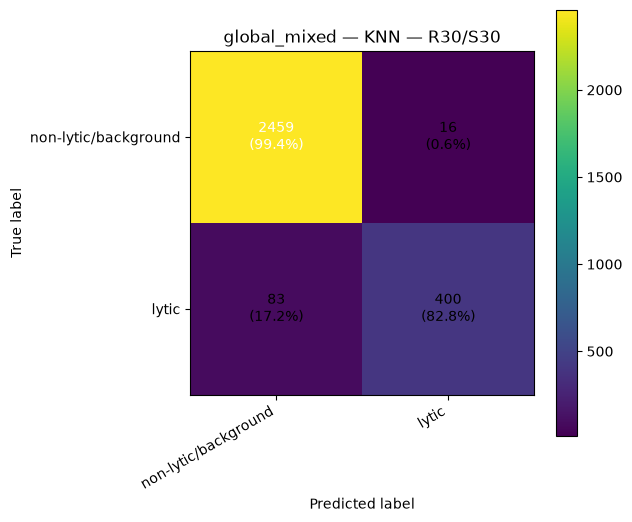

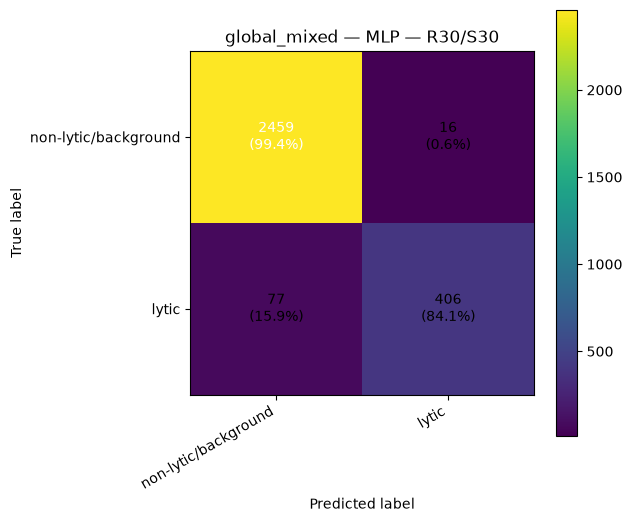

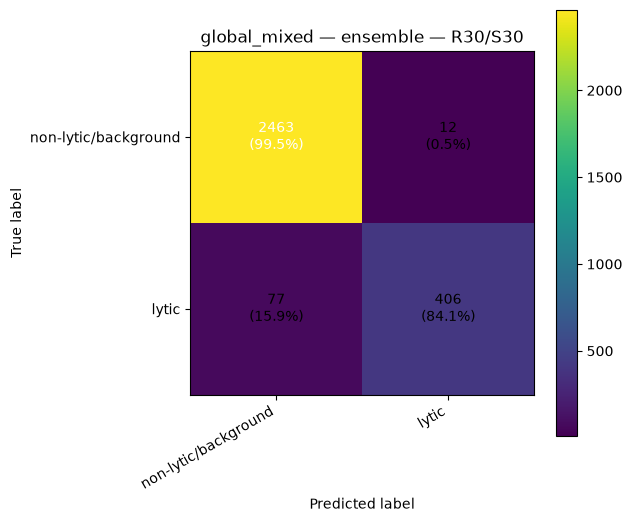

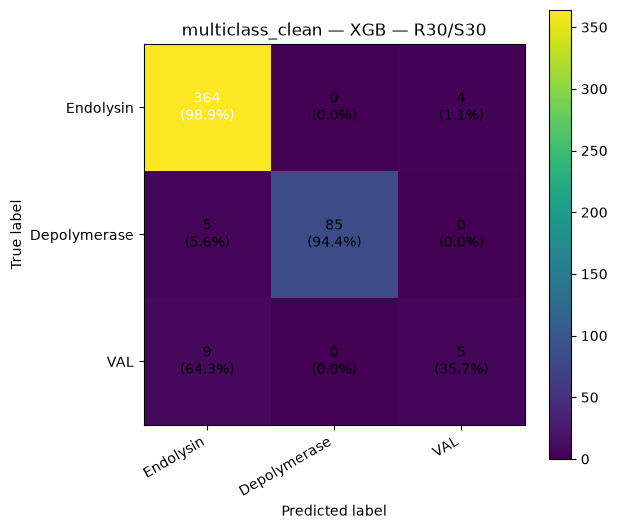

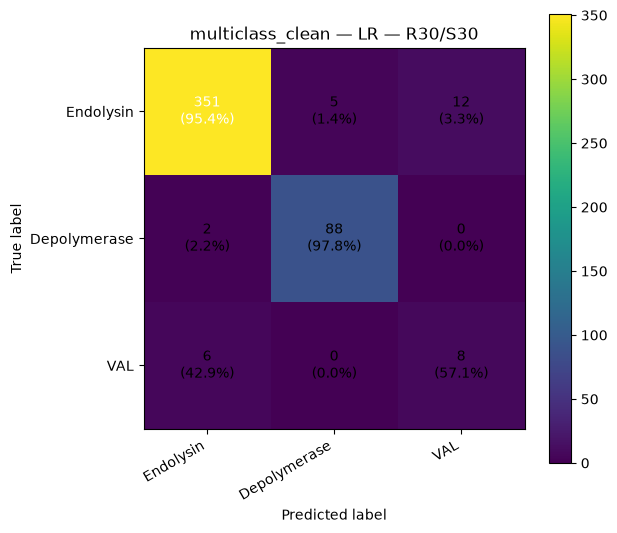

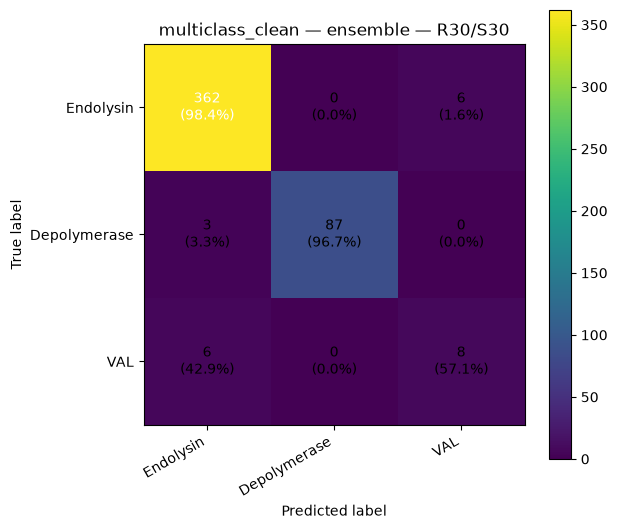

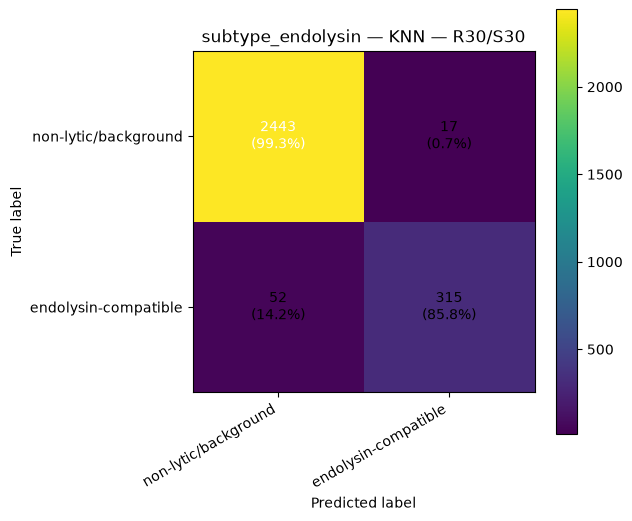

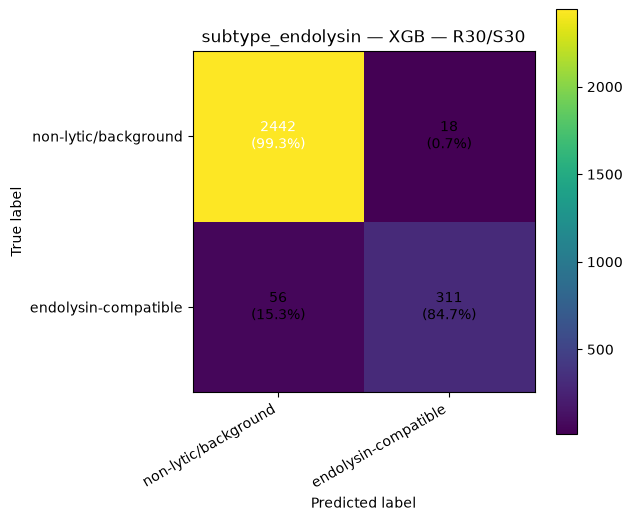

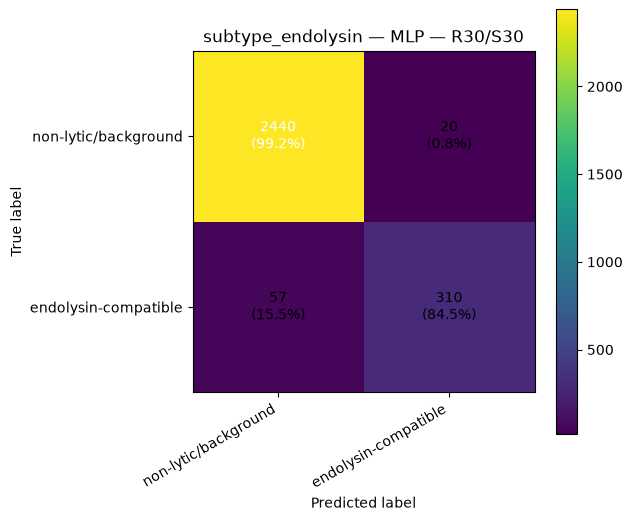

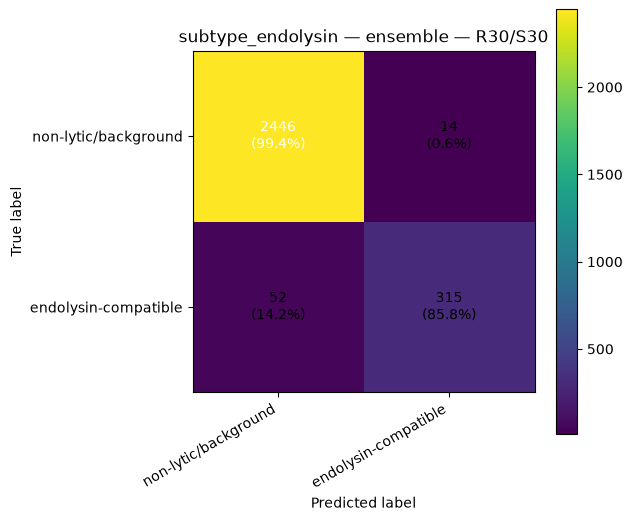

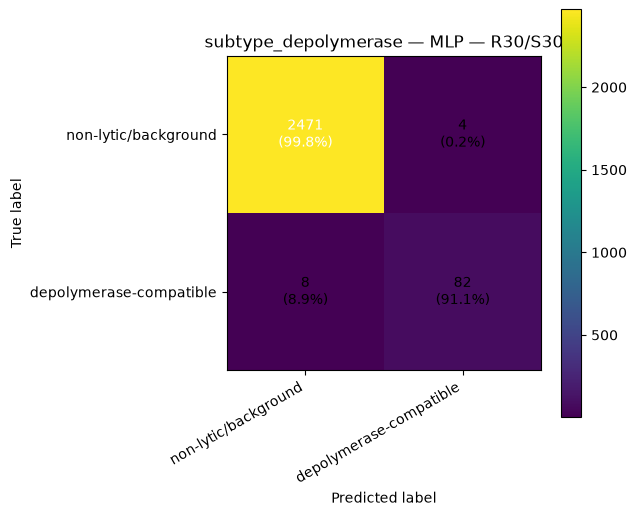

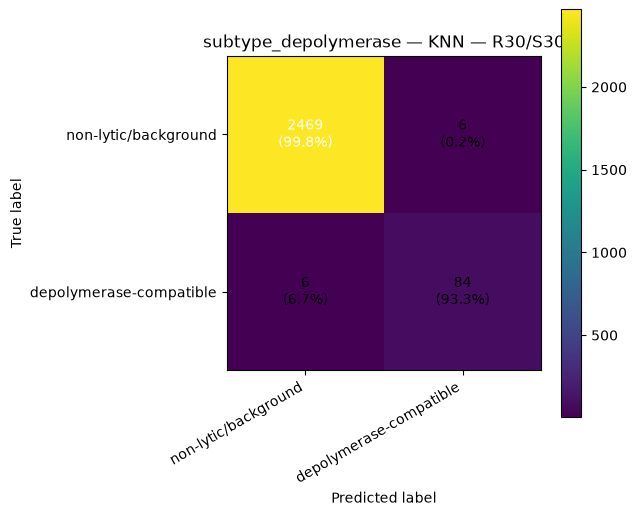

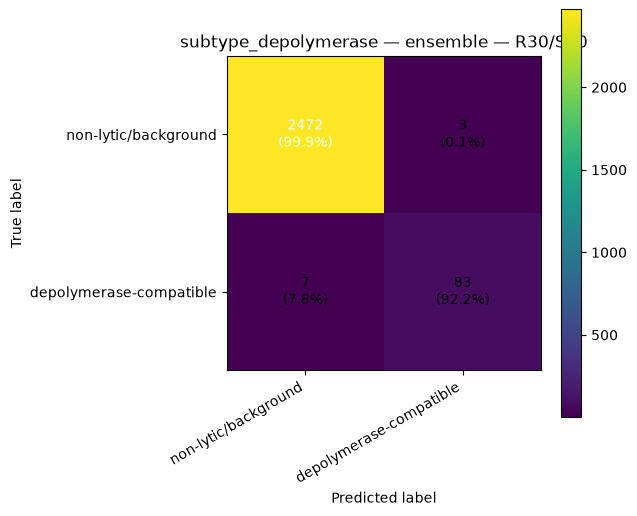

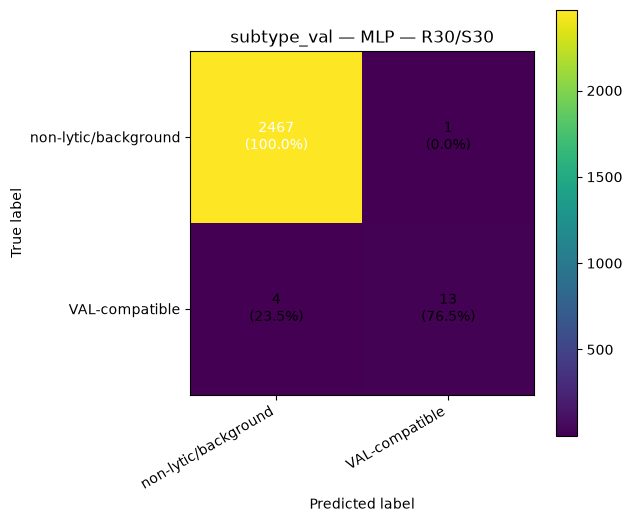

CONFUSION_FIGURES_OK


In [10]:

def save_figure(fig, stem):
    png = Path(str(stem) + ".png")
    pdf = Path(str(stem) + ".pdf")
    png.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return png, pdf


def plot_confusion(task, variant, y_true, y_pred):
    task_dir = FIG_DIR / task
    task_dir.mkdir(parents=True, exist_ok=True)

    if TASK_SPECS[task]["type"] == "binary":
        labels = [0, 1]
        display_labels = [
            TASK_SPECS[task]["negative_label"],
            TASK_SPECS[task]["positive_label"],
        ]
    else:
        labels = [0, 1, 2]
        display_labels = MULTICLASS_DISPLAY

    cm = confusion_matrix(y_true, y_pred, labels=labels)

    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    image = ax.imshow(cm, interpolation="nearest")
    fig.colorbar(image, ax=ax)
    ax.set(
        xticks=np.arange(len(display_labels)),
        yticks=np.arange(len(display_labels)),
        xticklabels=display_labels,
        yticklabels=display_labels,
        ylabel="True label",
        xlabel="Predicted label",
        title=f"{task} — {variant} — R30/S30",
    )
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

    threshold = cm.max() / 2 if cm.size else 0
    for i in range(cm.shape[0]):
        row_total = cm[i, :].sum()
        for j in range(cm.shape[1]):
            frac = cm[i, j] / row_total if row_total else np.nan
            text = f"{cm[i, j]}\n({frac:.1%})" if np.isfinite(frac) else str(cm[i, j])
            ax.text(
                j, i, text,
                ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black",
            )

    fig.tight_layout()
    safe_variant = re.sub(r"[^A-Za-z0-9_.-]+", "_", variant)
    return save_figure(
        fig,
        task_dir / f"confusion_{safe_variant}",
    )


figure_inventory = []

# Confusion matrices — every individual and final ensemble where applicable.
for task in PRODUCTION_TASKS:
    task_members = members[members["task"].eq(task)].sort_values("member_index")

    for rec in task_members.to_dict("records"):
        pred = individual_predictions[(task, rec["algorithm"])]
        png, pdf = plot_confusion(
            task,
            rec["algorithm"],
            pred["y_true"].to_numpy(dtype=int),
            pred["y_pred"].to_numpy(dtype=int),
        )
        figure_inventory.extend([
            {"task": task, "figure_type": "confusion", "variant": rec["algorithm"], "path": str(png)},
            {"task": task, "figure_type": "confusion", "variant": rec["algorithm"], "path": str(pdf)},
        ])

    component = frozen[frozen["task"].eq(task)].iloc[0]
    if str(component["option_type"]) == "ensemble":
        pred = final_predictions[task]
        png, pdf = plot_confusion(
            task,
            "ensemble",
            pred["y_true"].to_numpy(dtype=int),
            pred["y_pred"].to_numpy(dtype=int),
        )
        figure_inventory.extend([
            {"task": task, "figure_type": "confusion", "variant": "ensemble", "path": str(png)},
            {"task": task, "figure_type": "confusion", "variant": "ensemble", "path": str(pdf)},
        ])

print("CONFUSION_FIGURES_OK")


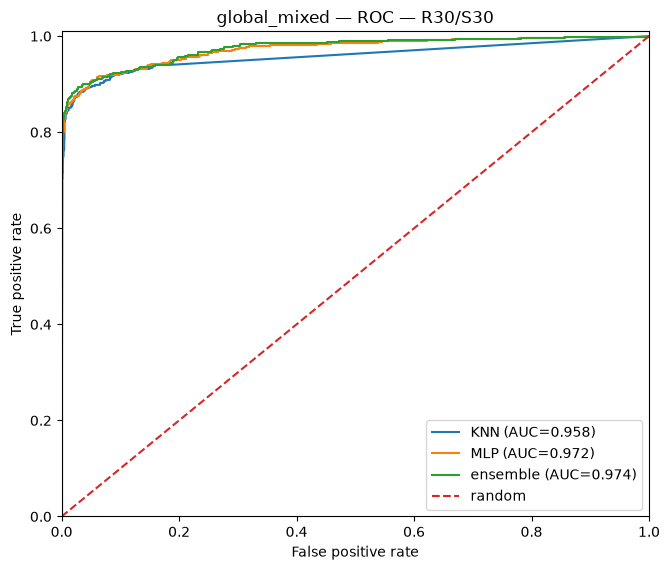

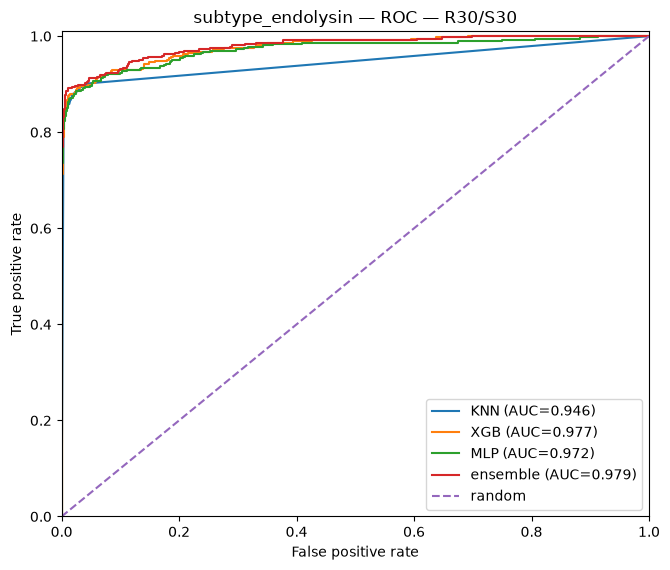

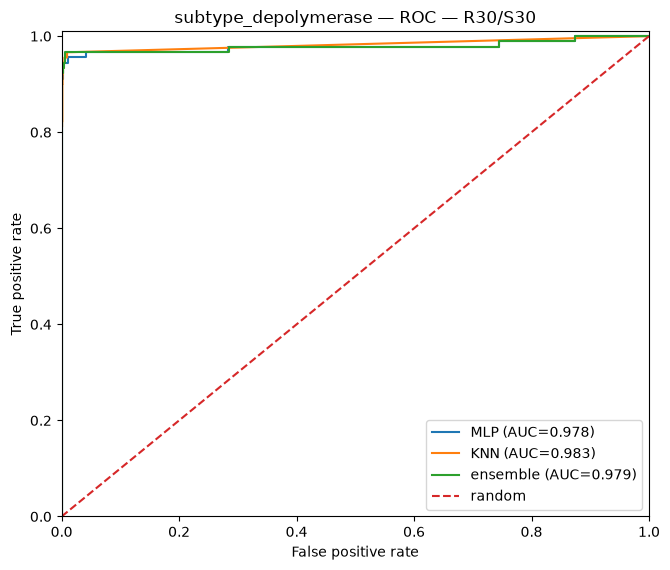

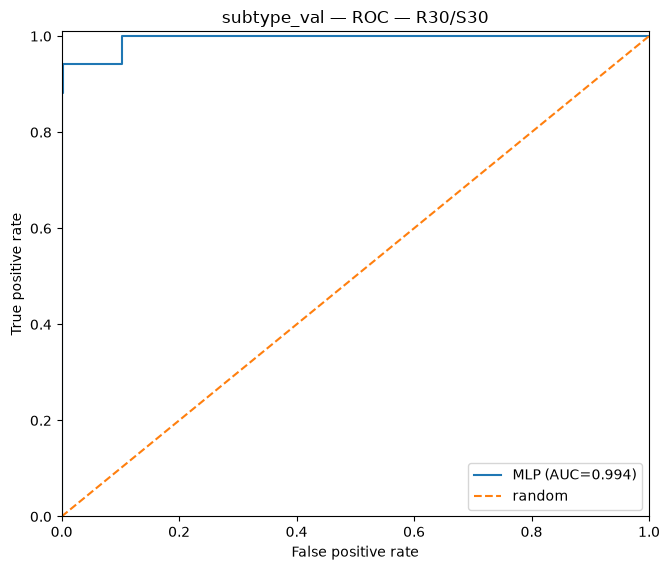

BINARY_ROC_FIGURES_OK


In [11]:

# Binary ROC overlays — one figure per binary task.
for task in [t for t in PRODUCTION_TASKS if TASK_SPECS[t]["type"] == "binary"]:
    subset = binary_metrics[binary_metrics["task"].eq(task)].copy()

    fig, ax = plt.subplots(figsize=(6.8, 5.8))

    for row in subset.itertuples(index=False):
        curves = binary_curves[
            binary_curves["task"].eq(task)
            & binary_curves["variant"].eq(row.variant)
            & binary_curves["curve"].eq("ROC")
        ]
        ax.plot(
            curves["x"],
            curves["y"],
            label=f"{row.variant} (AUC={row.roc_auc:.3f})",
        )

    ax.plot([0, 1], [0, 1], linestyle="--", label="random")
    ax.set(
        xlabel="False positive rate",
        ylabel="True positive rate",
        xlim=(0, 1),
        ylim=(0, 1.01),
        title=f"{task} — ROC — R30/S30",
    )
    ax.legend()
    fig.tight_layout()

    png, pdf = save_figure(fig, FIG_DIR / task / "roc_overlay")
    figure_inventory.extend([
        {"task": task, "figure_type": "ROC", "variant": "overlay", "path": str(png)},
        {"task": task, "figure_type": "ROC", "variant": "overlay", "path": str(pdf)},
    ])

print("BINARY_ROC_FIGURES_OK")


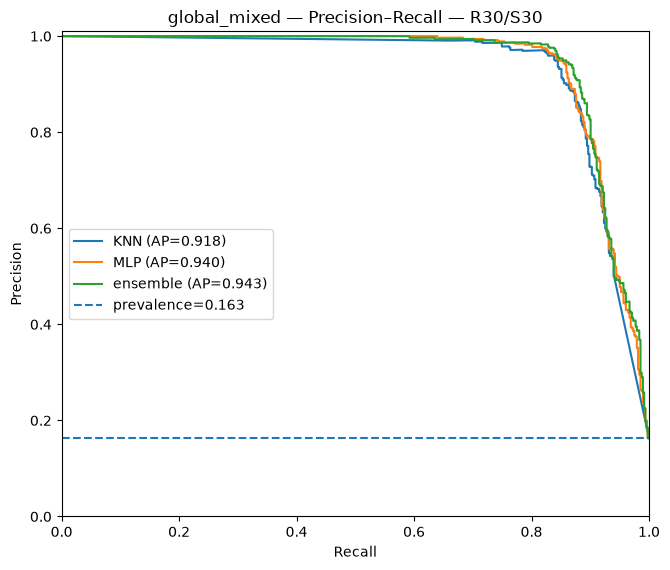

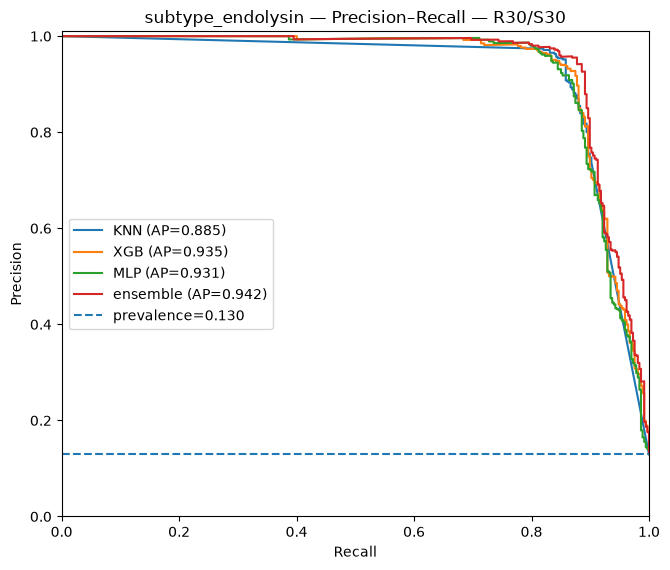

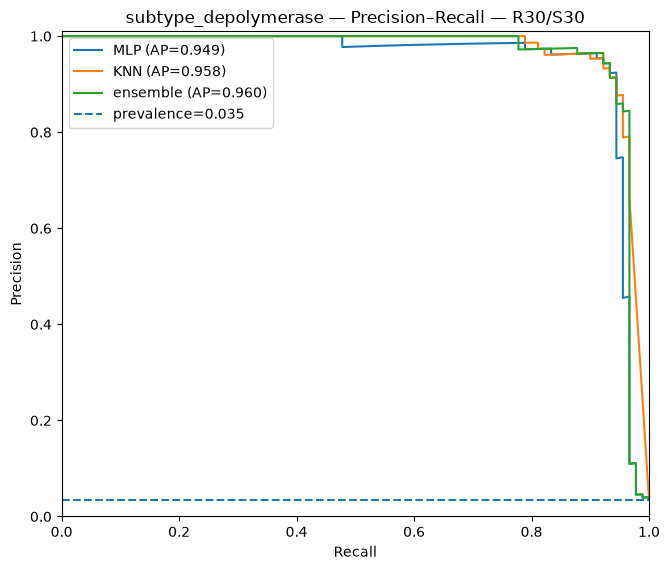

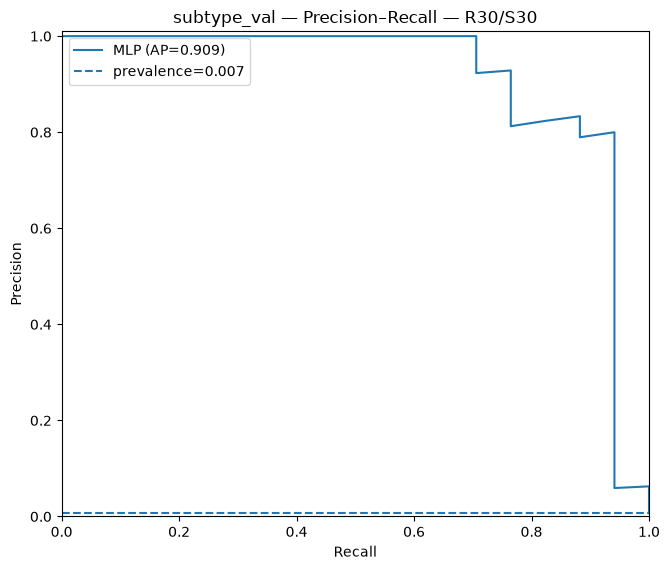

BINARY_PR_FIGURES_OK


In [12]:

# Binary Precision–Recall overlays — one figure per binary task.
for task in [t for t in PRODUCTION_TASKS if TASK_SPECS[t]["type"] == "binary"]:
    subset = binary_metrics[binary_metrics["task"].eq(task)].copy()

    fig, ax = plt.subplots(figsize=(6.8, 5.8))

    prevalence = float(subset.iloc[0]["prevalence"])
    for row in subset.itertuples(index=False):
        curves = binary_curves[
            binary_curves["task"].eq(task)
            & binary_curves["variant"].eq(row.variant)
            & binary_curves["curve"].eq("PR")
        ]
        ax.plot(
            curves["x"],
            curves["y"],
            label=f"{row.variant} (AP={row.average_precision:.3f})",
        )

    ax.axhline(prevalence, linestyle="--", label=f"prevalence={prevalence:.3f}")
    ax.set(
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1),
        ylim=(0, 1.01),
        title=f"{task} — Precision–Recall — R30/S30",
    )
    ax.legend()
    fig.tight_layout()

    png, pdf = save_figure(fig, FIG_DIR / task / "precision_recall_overlay")
    figure_inventory.extend([
        {"task": task, "figure_type": "PR", "variant": "overlay", "path": str(png)},
        {"task": task, "figure_type": "PR", "variant": "overlay", "path": str(pdf)},
    ])

print("BINARY_PR_FIGURES_OK")


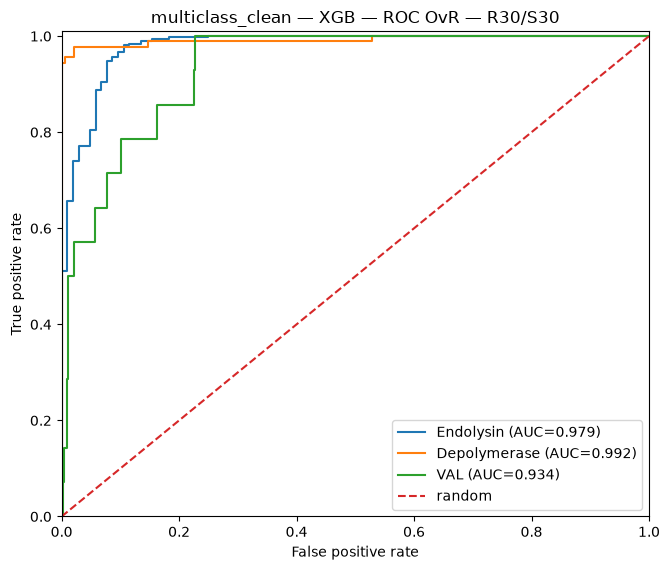

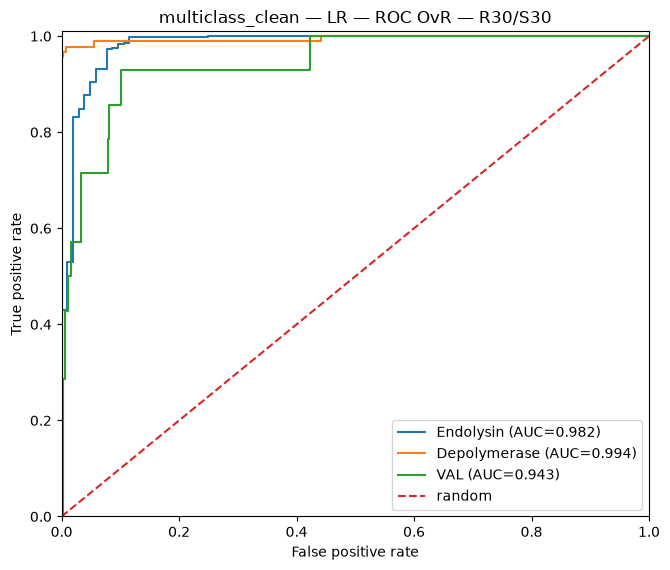

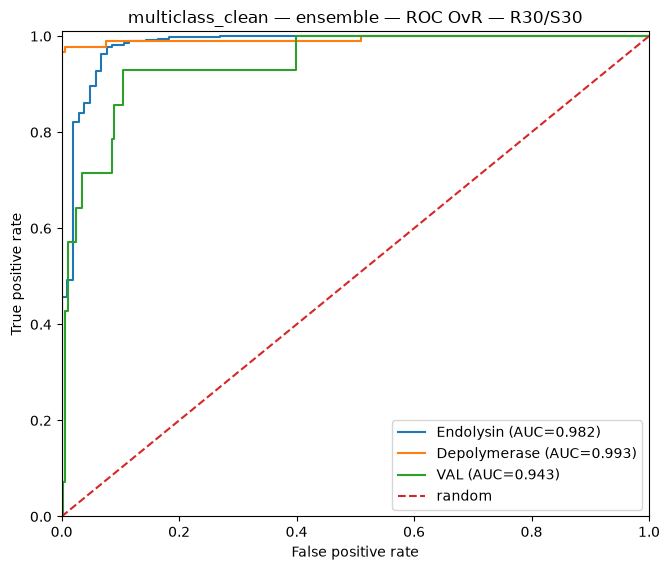

MULTICLASS_ROC_FIGURES_OK


In [13]:

# Multiclass ROC OvR: one figure per model variant to keep class curves readable.
for variant in multiclass_metrics["variant"]:
    subset = multiclass_curves[
        multiclass_curves["variant"].eq(variant)
        & multiclass_curves["curve"].eq("ROC")
    ]

    fig, ax = plt.subplots(figsize=(6.8, 5.8))

    for class_name, display_name in zip(MULTICLASS_ORDER, MULTICLASS_DISPLAY):
        curves = subset[subset["class"].eq(class_name)]
        auc = multiclass_per_class.loc[
            multiclass_per_class["variant"].eq(variant)
            & multiclass_per_class["class"].eq(class_name),
            "roc_auc_ovr",
        ].iloc[0]
        ax.plot(curves["x"], curves["y"], label=f"{display_name} (AUC={auc:.3f})")

    ax.plot([0, 1], [0, 1], linestyle="--", label="random")
    ax.set(
        xlabel="False positive rate",
        ylabel="True positive rate",
        xlim=(0, 1),
        ylim=(0, 1.01),
        title=f"multiclass_clean — {variant} — ROC OvR — R30/S30",
    )
    ax.legend()
    fig.tight_layout()

    png, pdf = save_figure(
        fig, FIG_DIR / "multiclass_clean" / f"roc_ovr_{variant}"
    )
    figure_inventory.extend([
        {"task": "multiclass_clean", "figure_type": "ROC_OvR", "variant": variant, "path": str(png)},
        {"task": "multiclass_clean", "figure_type": "ROC_OvR", "variant": variant, "path": str(pdf)},
    ])

print("MULTICLASS_ROC_FIGURES_OK")


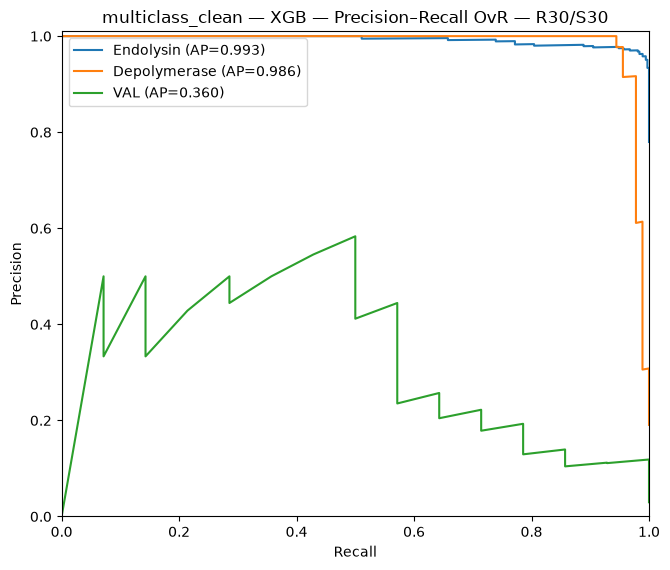

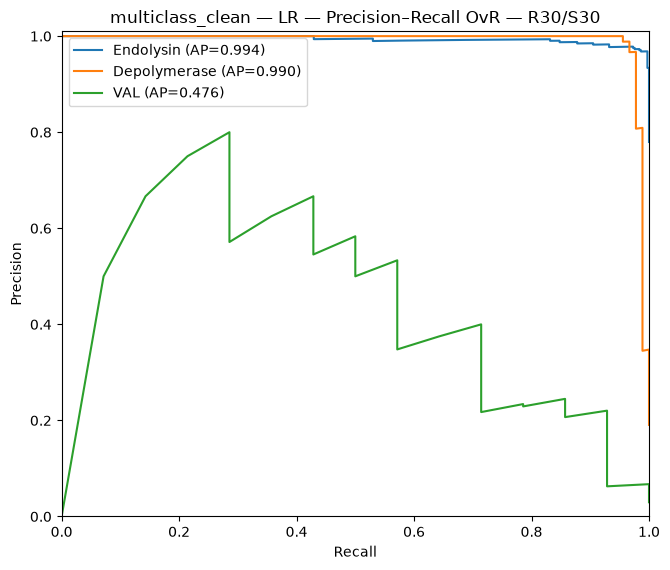

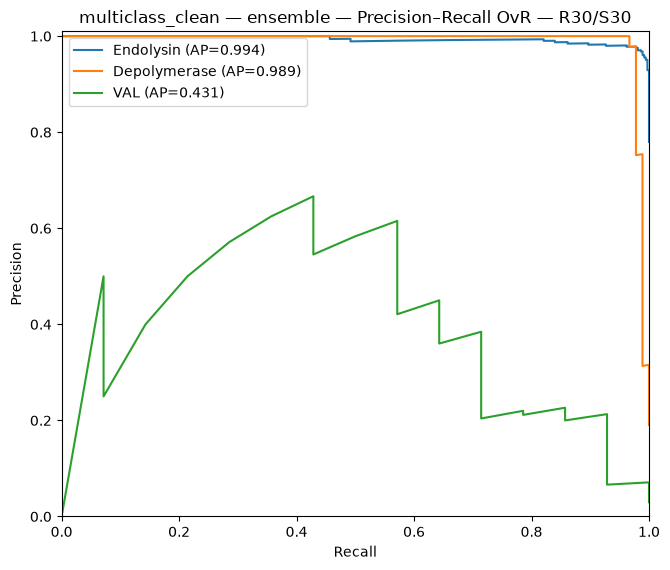

MULTICLASS_PR_FIGURES_OK


In [14]:

# Multiclass Precision–Recall OvR: one figure per model variant.
for variant in multiclass_metrics["variant"]:
    subset = multiclass_curves[
        multiclass_curves["variant"].eq(variant)
        & multiclass_curves["curve"].eq("PR")
    ]

    fig, ax = plt.subplots(figsize=(6.8, 5.8))

    for class_name, display_name in zip(MULTICLASS_ORDER, MULTICLASS_DISPLAY):
        curves = subset[subset["class"].eq(class_name)]
        ap = multiclass_per_class.loc[
            multiclass_per_class["variant"].eq(variant)
            & multiclass_per_class["class"].eq(class_name),
            "average_precision",
        ].iloc[0]
        ax.plot(curves["x"], curves["y"], label=f"{display_name} (AP={ap:.3f})")

    ax.set(
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1),
        ylim=(0, 1.01),
        title=f"multiclass_clean — {variant} — Precision–Recall OvR — R30/S30",
    )
    ax.legend()
    fig.tight_layout()

    png, pdf = save_figure(
        fig, FIG_DIR / "multiclass_clean" / f"precision_recall_ovr_{variant}"
    )
    figure_inventory.extend([
        {"task": "multiclass_clean", "figure_type": "PR_OvR", "variant": variant, "path": str(png)},
        {"task": "multiclass_clean", "figure_type": "PR_OvR", "variant": variant, "path": str(pdf)},
    ])

print("MULTICLASS_PR_FIGURES_OK")


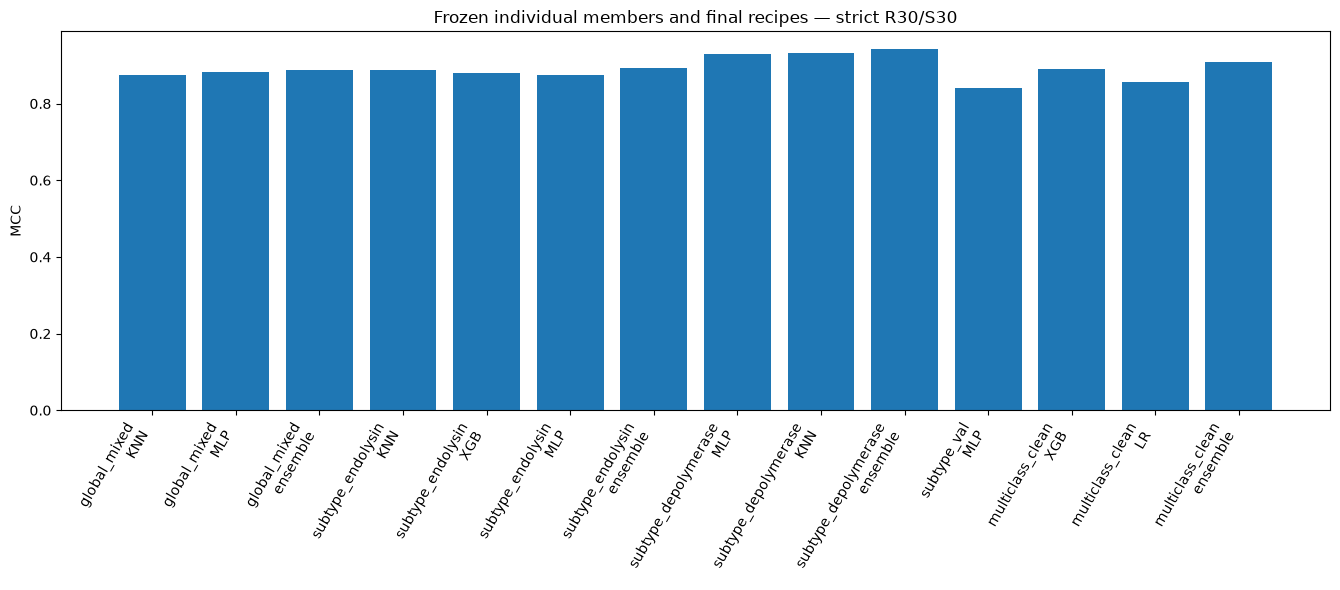

,task,variant,role,mcc
0,global_mixed,KNN,individual,0.873647
1,global_mixed,MLP,individual,0.881569
2,global_mixed,ensemble,final_recipe,0.886794
3,subtype_endolysin,KNN,individual,0.888853
4,subtype_endolysin,XGB,individual,0.880510
5,subtype_endolysin,MLP,individual,0.875648
6,subtype_endolysin,ensemble,final_recipe,0.893638
7,subtype_depolymerase,MLP,individual,0.929655
8,subtype_depolymerase,KNN,individual,0.930909
9,subtype_depolymerase,ensemble,final_recipe,0.941425


SUMMARY_FIGURE_OK


In [15]:

# Summary strict MCC figure.
summary_rows = []

for row in binary_metrics.itertuples(index=False):
    summary_rows.append({
        "task": row.task,
        "variant": row.variant,
        "role": row.role,
        "mcc": row.mcc,
    })
for row in multiclass_metrics.itertuples(index=False):
    summary_rows.append({
        "task": row.task,
        "variant": row.variant,
        "role": row.role,
        "mcc": row.mcc,
    })

strict_summary = pd.DataFrame(summary_rows)

labels = [
    f"{row.task}\n{row.variant}"
    for row in strict_summary.itertuples(index=False)
]
x = np.arange(len(strict_summary))

fig, ax = plt.subplots(figsize=(13.5, 6.0))
ax.bar(x, strict_summary["mcc"].to_numpy())
ax.set_xticks(x, labels, rotation=60, ha="right")
ax.set_ylabel("MCC")
ax.set_title("Frozen individual members and final recipes — strict R30/S30")
fig.tight_layout()

png, pdf = save_figure(fig, FIG_DIR / "rq29b_strict_mcc_summary")
figure_inventory.extend([
    {"task": "all", "figure_type": "strict_MCC", "variant": "summary", "path": str(png)},
    {"task": "all", "figure_type": "strict_MCC", "variant": "summary", "path": str(pdf)},
])

figure_inventory = pd.DataFrame(figure_inventory)
figure_inventory.to_csv(
    RQ29B_OUT / "rq29b_figure_inventory.tsv",
    sep="\t",
    index=False,
)

display(strict_summary)
print("SUMMARY_FIGURE_OK")


## 9. Individual-versus-final recipe comparison

,task,option_type,best_individual_variant,best_individual_mcc,final_variant,final_mcc,final_minus_best_individual_mcc,best_individual_roc_auc,final_roc_auc,best_individual_average_precision,final_average_precision,best_individual_macro_roc_auc,final_macro_roc_auc,best_individual_macro_average_precision,final_macro_average_precision
0,global_mixed,ensemble,MLP,0.881569,ensemble,0.886794,0.005225,0.972235,0.974254,0.940210,0.943065,NaN,NaN,NaN,NaN
1,multiclass_clean,ensemble,XGB,0.889758,ensemble,0.909655,0.019898,NaN,NaN,NaN,NaN,0.968271,0.972789,0.779784,0.804509
2,subtype_endolysin,ensemble,KNN,0.888853,ensemble,0.893638,0.004785,0.946026,0.979391,0.885271,0.942180,NaN,NaN,NaN,NaN
3,subtype_depolymerase,ensemble,KNN,0.930909,ensemble,0.941425,0.010516,0.982669,0.978510,0.957951,0.959812,NaN,NaN,NaN,NaN
4,subtype_val,single,MLP,0.841707,MLP,0.841707,0.000000,0.993684,0.993684,0.908716,0.908716,NaN,NaN,NaN,NaN


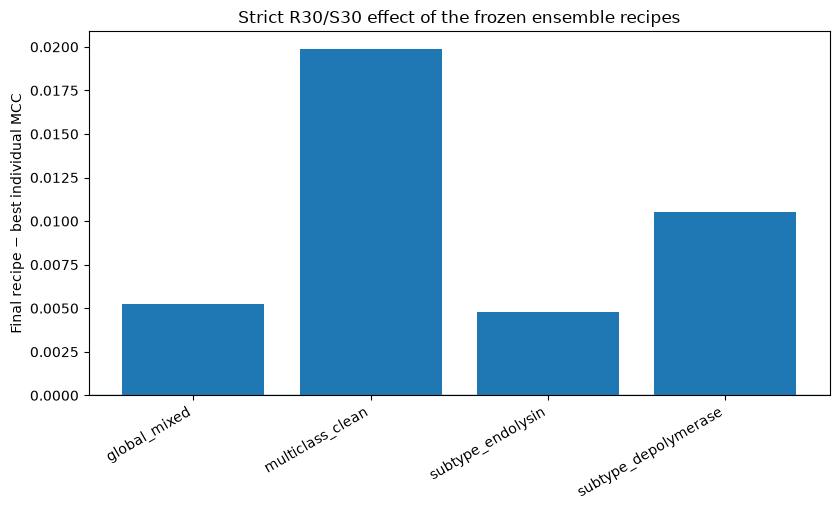

MEMBER_VS_FINAL_RECIPE_OK


In [16]:

comparison_rows = []

for task in PRODUCTION_TASKS:
    component = frozen[frozen["task"].eq(task)].iloc[0]

    if TASK_SPECS[task]["type"] == "binary":
        rows = binary_metrics[binary_metrics["task"].eq(task)]
        individuals = rows[rows["role"].eq("individual")]
        final_row = (
            rows[rows["role"].eq("final_recipe")].iloc[0]
            if (rows["role"].eq("final_recipe")).any()
            else individuals.iloc[0]
        )
        best_individual = individuals.sort_values("mcc", ascending=False).iloc[0]

        comparison_rows.append({
            "task": task,
            "option_type": component["option_type"],
            "best_individual_variant": best_individual["variant"],
            "best_individual_mcc": float(best_individual["mcc"]),
            "final_variant": final_row["variant"],
            "final_mcc": float(final_row["mcc"]),
            "final_minus_best_individual_mcc": float(
                final_row["mcc"] - best_individual["mcc"]
            ),
            "best_individual_roc_auc": float(best_individual["roc_auc"]),
            "final_roc_auc": float(final_row["roc_auc"]),
            "best_individual_average_precision": float(best_individual["average_precision"]),
            "final_average_precision": float(final_row["average_precision"]),
        })
    else:
        rows = multiclass_metrics[multiclass_metrics["task"].eq(task)]
        individuals = rows[rows["role"].eq("individual")]
        final_row = rows[rows["role"].eq("final_recipe")].iloc[0]
        best_individual = individuals.sort_values("mcc", ascending=False).iloc[0]

        comparison_rows.append({
            "task": task,
            "option_type": component["option_type"],
            "best_individual_variant": best_individual["variant"],
            "best_individual_mcc": float(best_individual["mcc"]),
            "final_variant": final_row["variant"],
            "final_mcc": float(final_row["mcc"]),
            "final_minus_best_individual_mcc": float(
                final_row["mcc"] - best_individual["mcc"]
            ),
            "best_individual_macro_roc_auc": float(best_individual["macro_roc_auc_ovr"]),
            "final_macro_roc_auc": float(final_row["macro_roc_auc_ovr"]),
            "best_individual_macro_average_precision": float(best_individual["macro_average_precision"]),
            "final_macro_average_precision": float(final_row["macro_average_precision"]),
        })

member_vs_final = pd.DataFrame(comparison_rows)
member_vs_final.to_csv(
    RQ29B_OUT / "rq29b_member_vs_final_recipe.tsv",
    sep="\t",
    index=False,
)

display(member_vs_final)

# Standalone ensemble effect figure.
ensemble_only = member_vs_final[member_vs_final["option_type"].eq("ensemble")].copy()

fig, ax = plt.subplots(figsize=(8.5, 5.2))
x = np.arange(len(ensemble_only))
ax.bar(x, ensemble_only["final_minus_best_individual_mcc"].to_numpy())
ax.axhline(0, linewidth=1)
ax.set_xticks(x, ensemble_only["task"], rotation=30, ha="right")
ax.set_ylabel("Final recipe − best individual MCC")
ax.set_title("Strict R30/S30 effect of the frozen ensemble recipes")
fig.tight_layout()

png, pdf = save_figure(fig, FIG_DIR / "rq29b_ensemble_gain_summary")
extra_figs = pd.DataFrame([
    {"task": "all", "figure_type": "ensemble_gain", "variant": "summary", "path": str(png)},
    {"task": "all", "figure_type": "ensemble_gain", "variant": "summary", "path": str(pdf)},
])
figure_inventory = pd.concat([figure_inventory, extra_figs], ignore_index=True)
figure_inventory.to_csv(
    RQ29B_OUT / "rq29b_figure_inventory.tsv",
    sep="\t",
    index=False,
)

print("MEMBER_VS_FINAL_RECIPE_OK")


## 10. Write task-level `performance.json` into the production bundle

In [17]:

performance_audit_rows = []

for task in PRODUCTION_TASKS:
    task_dir = MODEL_ROOT / "tasks" / task
    component = frozen[frozen["task"].eq(task)].iloc[0]
    align_task = config_alignment[config_alignment["task"].eq(task)].copy()

    if TASK_SPECS[task]["type"] == "binary":
        metric_table = binary_metrics[binary_metrics["task"].eq(task)].copy()
        per_class_payload = None
    else:
        metric_table = multiclass_metrics[multiclass_metrics["task"].eq(task)].copy()
        per_class_payload = multiclass_per_class[
            multiclass_per_class["task"].eq(task)
        ].to_dict("records")

    final_variant = (
        "ensemble"
        if str(component["option_type"]) == "ensemble"
        else members.loc[members["task"].eq(task), "algorithm"].iloc[0]
    )

    final_metrics = metric_table[
        metric_table["variant"].eq(final_variant)
    ]
    if len(final_metrics) != 1:
        raise RuntimeError(
            f"{task}: expected one final strict characterization row for {final_variant}."
        )

    payload = {
        "schema_version": "rq29b-performance-v1",
        "model_version": MODEL_VERSION,
        "task": task,
        "task_type": TASK_SPECS[task]["type"],
        "generated_utc": datetime.now(timezone.utc).isoformat(),
        "evaluation_basis": {
            "protocol": "held-out benchmark outer test",
            "R": STRICT_R,
            "S": STRICT_S,
            "representation": REPRESENTATION_ID,
            "threshold_binary": 0.5 if TASK_SPECS[task]["type"] == "binary" else None,
            "scope": (
                "recipe/strategy-level held-out characterization; "
                "not evaluation of final all-data refit weights"
            ),
            "training_fit_performance_reported": False,
            "outer_test_used_for_production_config_selection": False,
        },
        "configuration_alignment": align_task[
            [
                "algorithm",
                "strict_selected_config_id",
                "production_consensus_config_id",
                "strict_matches_production_consensus",
            ]
        ].to_dict("records"),
        "surface_context": {
            "mean_mcc": float(component["benchmark_mean_mcc"]),
            "worst_mcc": float(component["benchmark_worst_mcc"]),
            "strict_R30S30_mcc": float(component["benchmark_strict_R30S30_mcc"]),
        },
        "individual_members_strict": metric_table[
            metric_table["role"].eq("individual")
        ].to_dict("records"),
        "final_recipe_strict": final_metrics.iloc[0].to_dict(),
        "multiclass_per_class_strict": per_class_payload,
        "figure_directory": str((FIG_DIR / task).relative_to(ROOT)),
        "warnings": (
            [
                "VAL predictions are evidence-limited and should be interpreted cautiously."
            ]
            if task == "subtype_val"
            else []
        ),
    }

    performance_path = task_dir / "performance.json"
    performance_path.write_text(
        json.dumps(payload, indent=2, default=str),
        encoding="utf-8",
    )

    performance_audit_rows.append({
        "task": task,
        "performance_path": str(performance_path),
        "exists": performance_path.is_file(),
        "final_variant": final_variant,
        "strict_mcc": float(final_metrics.iloc[0]["mcc"]),
        "strict_matches_rq28": abs(
            float(final_metrics.iloc[0]["mcc"])
            - float(component["benchmark_strict_R30S30_mcc"])
        ) <= MCC_ATOL,
        "n_member_config_matches": int(
            align_task["strict_matches_production_consensus"].sum()
        ),
        "n_members": len(align_task),
    })

performance_audit = pd.DataFrame(performance_audit_rows)
performance_audit.to_csv(
    RQ29B_OUT / "rq29b_performance_json_audit.tsv",
    sep="\t",
    index=False,
)

display(performance_audit)
print("PERFORMANCE_JSON_WRITTEN")


,task,performance_path,exists,final_variant,strict_mcc,strict_matches_rq28,n_member_config_matches,n_members
0,global_mixed,/home/david/Desktop/colabs/inta_project/phagel...,True,ensemble,0.886794,True,0,2
1,multiclass_clean,/home/david/Desktop/colabs/inta_project/phagel...,True,ensemble,0.909655,True,1,2
2,subtype_endolysin,/home/david/Desktop/colabs/inta_project/phagel...,True,ensemble,0.893638,True,3,3
3,subtype_depolymerase,/home/david/Desktop/colabs/inta_project/phagel...,True,ensemble,0.941425,True,0,2
4,subtype_val,/home/david/Desktop/colabs/inta_project/phagel...,True,MLP,0.841707,True,0,1


PERFORMANCE_JSON_WRITTEN


## 11. Update release checksums and characterization manifest

In [18]:

# Preserve model weights; add characterization metadata to the release inventory.
inventory_rows = []
for p in sorted(MODEL_ROOT.rglob("*")):
    if not p.is_file():
        continue
    rel = p.relative_to(MODEL_ROOT).as_posix()
    if rel in {"manifest.json", "checksums.tsv"}:
        continue
    inventory_rows.append({
        "relative_path": rel,
        "bytes": int(p.stat().st_size),
        "sha256": sha256_file(p),
    })

updated_checksums = pd.DataFrame(inventory_rows)
updated_checksums.to_csv(
    MODEL_ROOT / "checksums.tsv", sep="\t", index=False
)

release_manifest = json.loads(
    (MODEL_ROOT / "manifest.json").read_text(encoding="utf-8")
)
release_manifest["characterization"] = {
    "stage": "RQ29B",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "protocol": "strict R30/S30 held-out benchmark characterization",
    "results_root": str(RQ29B_OUT.relative_to(ROOT)),
    "performance_json_per_task": True,
    "training_fit_performance_reported": False,
    "n_tasks": 5,
    "n_individual_members": 10,
    "n_final_ensembles": 4,
}
release_manifest["n_payload_files_checksummed"] = int(len(updated_checksums))

(MODEL_ROOT / "manifest.json").write_text(
    json.dumps(release_manifest, indent=2, default=str),
    encoding="utf-8",
)

rq29b_manifest = {
    "stage": "RQ29B",
    "model_version": MODEL_VERSION,
    "characterization_protocol": "R30/S30 held-out outer test",
    "n_tasks": 5,
    "n_individual_members": 10,
    "n_final_ensembles": 4,
    "n_binary_metric_rows": int(len(binary_metrics)),
    "n_multiclass_metric_rows": int(len(multiclass_metrics)),
    "n_multiclass_per_class_rows": int(len(multiclass_per_class)),
    "n_figures_png_pdf": int(len(figure_inventory)),
    "production_bundle_modified_only_by_metadata": True,
    "joblib_files_rewritten": False,
    "performance_json_per_task": True,
    "strict_characterization_is_not_final_refit_test_performance": True,
}
(RQ29B_OUT / "rq29b_manifest.json").write_text(
    json.dumps(rq29b_manifest, indent=2),
    encoding="utf-8",
)

print("RELEASE_CHARACTERIZATION_METADATA_UPDATED")


RELEASE_CHARACTERIZATION_METADATA_UPDATED


## 12. Final RQ29B gates

In [19]:

required_exports = [
    "rq29b_production_model_health.tsv",
    "rq29b_config_alignment.tsv",
    "rq29b_individual_prediction_audit.tsv",
    "rq29b_multiclass_probability_schema_audit.tsv",
    "rq29b_final_recipe_reconstruction.tsv",
    "rq29b_binary_strict_metrics.tsv",
    "rq29b_binary_curve_points.tsv",
    "rq29b_multiclass_strict_metrics.tsv",
    "rq29b_multiclass_per_class_metrics.tsv",
    "rq29b_multiclass_curve_points.tsv",
    "rq29b_confusion_counts.tsv",
    "rq29b_surface_performance_context.tsv",
    "rq29b_figure_inventory.tsv",
    "rq29b_member_vs_final_recipe.tsv",
    "rq29b_performance_json_audit.tsv",
    "rq29b_manifest.json",
]

assert model_health["health_ok"].all()
assert len(config_alignment) == 10
assert len(individual_audit) == 10
assert len(multiclass_schema_audit) == 2
assert multiclass_schema_audit['argmax_agreement'].ge(0.999999).all()
assert multiclass_schema_audit['biological_reconstruction_agreement'].ge(0.999999).all()
assert individual_audit["reconstruction_ok"].all()
assert len(ensemble_audit) == 5
assert ensemble_audit["reconstruction_ok"].all()

# 4 binary tasks:
# global 2 individual + ensemble = 3
# endolysin 3 individual + ensemble = 4
# DPO 2 individual + ensemble = 3
# VAL 1 individual = 1
assert len(binary_metrics) == 11

# multiclass = XGB, LR, final ensemble
assert len(multiclass_metrics) == 3
assert len(multiclass_per_class) == 9

assert len(performance_audit) == 5
assert performance_audit["exists"].all()
assert performance_audit["strict_matches_rq28"].all()

# 10 individual confusion matrices + 4 ensemble confusion matrices = 14;
# each exported PNG + PDF => 28 files.
confusion_figs = figure_inventory[
    figure_inventory["figure_type"].eq("confusion")
]
assert len(confusion_figs) == 28

# Binary ROC + PR: 4 tasks × 2 figure types × 2 formats = 16.
# Multiclass ROC/PR: 3 variants × 2 types × 2 formats = 12.
# Summary MCC: 2 files.
# Ensemble gain summary: 2 files.
# Total figure inventory = 60.
assert len(figure_inventory) == 60

assert all((RQ29B_OUT / name).is_file() for name in required_exports)

# Recheck updated release checksums.
published_checksums = pd.read_csv(
    MODEL_ROOT / "checksums.tsv", sep="\t", low_memory=False
)
checksum_failures = []
for row in published_checksums.itertuples(index=False):
    p = MODEL_ROOT / row.relative_path
    if not p.is_file() or sha256_file(p) != row.sha256:
        checksum_failures.append(row.relative_path)
assert not checksum_failures, checksum_failures

# All five tasks must now carry performance.json.
assert all(
    (MODEL_ROOT / "tasks" / task / "performance.json").is_file()
    for task in PRODUCTION_TASKS
)

print("RQ29B_EXECUTION_GATES_OK")
print("Production-model health rows:", len(model_health))
print("Individual held-out members characterized:", len(individual_audit))
print("Multiclass schema audits:", len(multiclass_schema_audit))
print("Final recipes reconstructed:", len(ensemble_audit))
print("Binary strict metric rows:", len(binary_metrics))
print("Multiclass strict metric rows:", len(multiclass_metrics))
print("Multiclass per-class rows:", len(multiclass_per_class))
print("Task performance.json files:", len(performance_audit))
print("Figure files (PNG + PDF):", len(figure_inventory))
print("Strict/production config matches:", int(config_alignment['strict_matches_production_consensus'].sum()), "/", len(config_alignment))
print()
print(
    "Interpretation status: execution gates passed. "
    "Assign REAL-DATA PASS only after the executed notebook is inspected for "
    "zero errors/stderr, model-health status, quantitative coherence, and figure outputs."
)


RQ29B_EXECUTION_GATES_OK
Production-model health rows: 10
Individual held-out members characterized: 10
Multiclass schema audits: 2
Final recipes reconstructed: 5
Binary strict metric rows: 11
Multiclass strict metric rows: 3
Multiclass per-class rows: 9
Task performance.json files: 5
Figure files (PNG + PDF): 60
Strict/production config matches: 4 / 10

Interpretation status: execution gates passed. Assign REAL-DATA PASS only after the executed notebook is inspected for zero errors/stderr, model-health status, quantitative coherence, and figure outputs.



## Interpretation guardrails

- `R30/S30` is the canonical held-out characterization regime, not a production training regime.
- The final all-data `.joblib` weights are **not** evaluated on their fitting evidence.
- Curves and confusion matrices characterize the frozen recipe under strict held-out benchmark conditions.
- `performance.json` explicitly records whether each strict-cell configuration matches the RQ29A production consensus configuration.
- Ensemble probabilities are reconstructed by exact unweighted soft voting over aligned member predictions.
- Binary subtype outputs remain compatibility diagnostics.
- VAL remains evidence-limited.
- RQ29C will consume the serialized bundle and its characterization metadata to implement the reusable inference core and FASTA CLI.
